<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## 0. Settings
Band power for all 60 final sessions with the new trial filter (trials_filtered.csv, keep == True; all long_prob blocks)
and the new bad-channel list (extra_bad_channels.csv, removed before referencing).
Two references: CMR (global median) and LOCAL (median of channels 30–200 µm away).
Output: one file per session and reference in data\analysis_main\band_power_v3 (CMR) and band_power_v3_localref (LOCAL).
The old files (band_power_v1, v2, v2_localref) are not touched.

<div>

In [1]:
# %%
# ── 0. SETTINGS (rebuilt 2026-11-05 after the deletion of analysis_main: all outputs now in amir_data\data) ──
import os, sys, time, glob, pickle, importlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", message="The following channels did not have enough neighbors")
MAIN      = r"C:\Users\ar687\Documents\GitHub\AmirAnalysis\main"
sys.path.insert(0, MAIN)
import functions as fn
importlib.reload(fn)

DATA_ROOT = r"O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data"
PROC      = os.path.join(DATA_ROOT, "2_processed")
AMIR      = os.path.join(DATA_ROOT, "amir_data")
DATA_OUT  = os.path.join(AMIR, "data")                                         # NEW home of all computed data
TABLES    = os.path.join(MAIN, "tables")
FIGS      = os.path.join(MAIN, "figures", "06_band_power")
BP_DIRS   = {"CMR":   os.path.join(DATA_OUT, "band power", "CMR"),
             "LOCAL": os.path.join(DATA_OUT, "band power", "LOCAL")}
BURST_DIR = os.path.join(DATA_OUT, "Bursts detection")                         # Karvat 2021 (Golan) method, 50-ms bins; beta + gamma, CMR + LOCAL                              # beta + gamma, CMR + LOCAL
EXACT_DIR = os.path.join(DATA_OUT, "Bursts detection exact times")             # same method, exact burst times (beta)
ALL_DIR   = os.path.join(DATA_OUT, "Beta and gamma bursts across channels")  # whole probe, LOCAL
for d in [FIGS, *BP_DIRS.values(), BURST_DIR, EXACT_DIR]:
    os.makedirs(d, exist_ok=True)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40)

final = pd.read_csv(os.path.join(TABLES, "final_sessions.csv"), dtype={"rat": str})
XB    = pd.read_csv(os.path.join(TABLES, "extra_bad_channels.csv"))
TR    = pd.read_csv(os.path.join(TABLES, "trials_filtered.csv"), dtype={"rat": str}, low_memory=False)
K     = TR[TR["keep"]].copy()
TEST  = "20260529_r0000136_wt_1318"

# representative channels (rule 1.13b): the original file was deleted; values from the saved 06 output (identical)
REP_FILE = os.path.join(TABLES, "representative_channels.csv")
if not os.path.exists(REP_FILE):
    pd.DataFrame([
        {"rat": 134, "region": "Cg1", "x": 750, "y": 3105}, {"rat": 134, "region": "IL", "x": 250, "y": 375}, {"rat": 134, "region": "PL", "x": 532, "y": 1845},
        {"rat": 135, "region": "Cg1", "x": 250, "y": 4020}, {"rat": 135, "region": "IL", "x": 0,   "y": 1065}, {"rat": 135, "region": "PL", "x": 282, "y": 2145},
        {"rat": 136, "region": "Cg1", "x": 32,  "y": 3255}, {"rat": 136, "region": "IL", "x": 250, "y": 585}, {"rat": 136, "region": "PL", "x": 250, "y": 2430}
    ]).to_csv(REP_FILE, index=False)
REP   = pd.read_csv(REP_FILE)
CHREG = pd.read_csv(os.path.join(TABLES, "channel_regions_all.csv"))
CHREG["channel_id"] = CHREG["channel_id"].astype(str)

print(f"final sessions: {len(final)} | kept trials: {len(K)} | extra bad channel rows: {len(XB)} (expected 107)")
print("kept trials with a tone, by label:", K.groupby("label")["tone_neural_s"].apply(lambda v: v.notna().sum()).to_dict())
print("output folders:", {"band power": list(BP_DIRS.values()), "bursts 50ms": BURST_DIR, "bursts exact": EXACT_DIR})
print("representative channels:", REP[["rat", "region", "x", "y"]].to_dict("records"))

final sessions: 60 | kept trials: 8615 | extra bad channel rows: 107 (expected 107)
kept trials with a tone, by label: {'correct': 4486, 'early': 0, 'late': 1549}
output folders: {'band power': ['O:\\archive\\projects\\2020_euSNN\\Neuropixels_RT_mPFC\\data\\amir_data\\data\\band power\\CMR', 'O:\\archive\\projects\\2020_euSNN\\Neuropixels_RT_mPFC\\data\\amir_data\\data\\band power\\LOCAL'], 'bursts 50ms': 'O:\\archive\\projects\\2020_euSNN\\Neuropixels_RT_mPFC\\data\\amir_data\\data\\Bursts detection', 'bursts exact': 'O:\\archive\\projects\\2020_euSNN\\Neuropixels_RT_mPFC\\data\\amir_data\\data\\Bursts detection exact times'}
representative channels: [{'rat': 134, 'region': 'Cg1', 'x': 750, 'y': 3105}, {'rat': 134, 'region': 'IL', 'x': 250, 'y': 375}, {'rat': 134, 'region': 'PL', 'x': 532, 'y': 1845}, {'rat': 135, 'region': 'Cg1', 'x': 250, 'y': 4020}, {'rat': 135, 'region': 'IL', 'x': 0, 'y': 1065}, {'rat': 135, 'region': 'PL', 'x': 282, 'y': 2145}, {'rat': 136, 'region': 'Cg1', 'x':

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## 1. Loading with CMR and LOCAL reference (test)
fn.load_session(..., refs=("CMR", "LOCAL")): extra bad channels removed first, then CMR (global median) and LOCAL
(median of the channels 30–200 µm away, SpikeInterface; same as band_power_v2_localref, 2026-10-20).
Test: channel count and signal size (RMS of 10 s, median over channels) in both references.

<div>

In [2]:
# %%
# ── 1. LOAD WITH CMR + LOCAL (test session) ──
importlib.reload(fn)
recs, removed = fn.load_session(PROC, TEST, XB, refs=("original", "CMR", "LOCAL"))
fs = recs["CMR"].get_sampling_frequency(); mid = recs["CMR"].get_num_samples() // 2
for ref, rec in recs.items():
    x = rec.get_traces(start_frame=mid, end_frame=mid + int(10 * fs), return_in_uV=True)
    print(f"{ref:8s}: {rec.get_num_channels()} channels | RMS (10 s, median over channels) {np.median(x.std(axis=0)):.1f} µV")
print("extra bad removed:", removed)

original: 383 channels | RMS (10 s, median over channels) 72.7 µV
CMR     : 383 channels | RMS (10 s, median over channels) 44.8 µV
LOCAL   : 383 channels | RMS (10 s, median over channels) 22.2 µV
extra bad removed: []


<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## 2. Test band power on one session (CMR)
fn.band_power_session on 20260529_r0000136_wt_1318, CMR, all kept trials (all long_prob blocks).
Conditions for the time courses and spectra: correct / early / late × long / short, plus "early long (hold>0.3)"
(early long trials held > 0.3 s, as in the old files) -> both early-long versions are saved; window values are saved per trial,
so any trial selection is possible later for them.
Sanity check: theta 4–7 hold vs pre, correct long, median over channels (2026-10-19 test: +30.7 %).
The file is saved in band_power_v3 (the loop in step 3 then skips this session).

<div>

In [6]:
# %%
# ── 3. TEST BAND POWER ON ONE SESSION (CMR) ──
importlib.reload(fn)
recs, removed = fn.load_session(PROC, TEST, XB, refs=("CMR",))
trs = fn.session_trials(K, TEST)
print(f"{TEST}: {recs['CMR'].get_num_channels()} channels | {len(trs)} kept trials")

t0 = time.time()
r = fn.band_power_session(recs["CMR"], trs, os.path.join(BP_DIRS["CMR"], TEST + ".pkl"),
                          meta_extra={"session": TEST, "ref": "CMR", "extra_bad_removed": removed})
print(f"done in {(time.time() - t0) / 60:.1f} min | trials used {r['meta']['n_trials']}")

T, lp = r["trials"], r["logpow"]
cl = ((T["label"] == "correct") & (T["type"] == "long")).values
print(f"\ncorrect long trials: {cl.sum()}")
for b in fn.MAIN_BANDS:
    d = (lp[b]["hold"][cl] - lp[b]["pre"][cl]).mean(axis=0)                  # per channel, mean over trials
    print(f"  {b:13s} hold vs pre: median over channels {100 * (10 ** np.median(d) - 1):+.1f} %")
print("\ncurve conditions:", list(r["curves"]["Press"]["theta 4-7"]))
print("trials per condition (spectra, pre window):", r["spec_n"]["pre"])

20260529_r0000136_wt_1318: 383 channels | 139 kept trials
    channels 0-64 of 383 done (45 s)
    channels 65-129 of 383 done (79 s)
    channels 130-194 of 383 done (113 s)
    channels 195-259 of 383 done (147 s)
    channels 260-324 of 383 done (181 s)
    channels 325-382 of 383 done (211 s)
done in 3.5 min | trials used 139

correct long trials: 49
  delta 1-3     hold vs pre: median over channels +5.1 %
  theta 4-7     hold vs pre: median over channels +30.7 %
  alpha 8-12    hold vs pre: median over channels +18.5 %
  beta 13-29    hold vs pre: median over channels +4.3 %
  lowG 30-60    hold vs pre: median over channels +3.9 %
  highG 61-100  hold vs pre: median over channels -3.7 %

curve conditions: ['correct long', 'correct short', 'early long', 'early short', 'late long', 'late short', 'early long (hold>0.3)']
trials per condition (spectra, pre window): {'correct long': 49, 'correct short': 48, 'early long': 15, 'early short': 2, 'late long': 3, 'late short': 22, 'early lo

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## 3. Bursts: test on one session (CMR and LOCAL)
fn.bursts_session: Karvat et al. 2021 rule (as cell 2.6 of analysis_main), one representative channel per region (PL, IL, Cg1; 1.13b rule).
Beta 15–30 Hz exactly as before (7 cycles); gamma 30–100 Hz added (10 cycles, 48–52 Hz set to 0 because of the notch).
Theta and NeuroDSP dropped. Output: data\analysis_main\bursts_karvat2021_v2\<session>.npz (+ _trials.csv).
Note: gamma is a wide band (~70 frequency rows) -> its occupancy is much higher than beta's; compare conditions within a band.

<div>

In [7]:
# %%
# ── 3. BURSTS: TEST ON ONE SESSION (CMR + LOCAL) ──
importlib.reload(fn)
recs, removed = fn.load_session(PROC, TEST, XB, refs=("CMR", "LOCAL"))
rat = final.set_index("session").loc[TEST, "rat"]
t0 = time.time()
z = fn.bursts_session(recs, fn.session_trials(K, TEST), REP, CHREG, TEST, rat, os.path.join(BURST_DIR, TEST + ".npz"))
print(f"\ndone in {(time.time() - t0) / 60:.1f} min")
print("channels:", {k: (str(v[0]), float(z[k.replace('channel', 'distance_um')][0])) for k, v in z.items() if k.endswith("|channel")})

    CMR Cg1 beta 15-30: occupancy 0.253 (9 s)
    CMR Cg1 gamma 30-100: occupancy 0.503 (22 s)
    CMR IL beta 15-30: occupancy 0.268 (25 s)
    CMR IL gamma 30-100: occupancy 0.502 (37 s)
    CMR PL beta 15-30: occupancy 0.269 (41 s)
    CMR PL gamma 30-100: occupancy 0.512 (53 s)
    LOCAL Cg1 beta 15-30: occupancy 0.251 (59 s)
    LOCAL Cg1 gamma 30-100: occupancy 0.490 (72 s)
    LOCAL IL beta 15-30: occupancy 0.274 (75 s)
    LOCAL IL gamma 30-100: occupancy 0.511 (87 s)
    LOCAL PL beta 15-30: occupancy 0.270 (91 s)
    LOCAL PL gamma 30-100: occupancy 0.500 (103 s)

done in 1.7 min
channels: {'CMR|Cg1|channel': ('imec0.ap#AP99', 0.0), 'CMR|IL|channel': ('imec0.ap#AP174', 0.0), 'CMR|PL|channel': ('imec0.ap#AP36', 0.0), 'LOCAL|Cg1|channel': ('imec0.ap#AP99', 0.0), 'LOCAL|IL|channel': ('imec0.ap#AP174', 0.0), 'LOCAL|PL|channel': ('imec0.ap#AP36', 0.0)}


<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## 4. Bursts: all final sessions (loop, CMR + LOCAL)
Same as step 3 for every final session; finished sessions are skipped; errors -> tables\bursts_errors.csv.

<div>

In [3]:
# %%
# ── 4. BURSTS: ALL FINAL SESSIONS ──
importlib.reload(fn)
RUN_BURSTS = True
todo = [s for s in final["session"] if not os.path.exists(os.path.join(BURST_DIR, s + ".npz"))]
print(f"bursts: {len(final) - len(todo)} done, {len(todo)} to do", flush=True)
if RUN_BURSTS:
    t_all = time.time()
    for i, s in enumerate(todo, 1):
        t0 = time.time()
        try:
            recs, _ = fn.load_session(PROC, s, XB, refs=("CMR", "LOCAL"))
            rat = final.set_index("session").loc[s, "rat"]
            fn.bursts_session(recs, fn.session_trials(K, s), REP, CHREG, s, rat, os.path.join(BURST_DIR, s + ".npz"), verbose=False)
            print(f"[{i}/{len(todo)}] {s}: ok ({(time.time() - t0) / 60:.1f} min)", flush=True)
        except Exception as e:
            print(f"[{i}/{len(todo)}] {s}: ERROR {e!r}", flush=True)
            pd.DataFrame([{"session": s, "error": repr(e)}]).to_csv(os.path.join(TABLES, "bursts_errors.csv"), mode="a",
                         header=not os.path.exists(os.path.join(TABLES, "bursts_errors.csv")), index=False)
    print(f"bursts finished in {(time.time() - t_all) / 60:.0f} min", flush=True)

bursts: 3 done, 57 to do


[1/57] 20260511_r0000136_wt_0930: ok (1.1 min)
[2/57] 20260511_r0000136_wt_1832: ok (1.4 min)
[3/57] 20260512_r0000136_wt_1054: ok (1.9 min)
[4/57] 20260513_r0000136_wt_1729: ok (0.6 min)
[5/57] 20260514_r0000136_wt_1317: ok (1.6 min)
[6/57] 20260515_r0000135_wt_1953: ok (1.7 min)
[7/57] 20260515_r0000135_wt_1957: ok (0.7 min)
[8/57] 20260515_r0000136_wt_1817: ok (2.4 min)
[9/57] 20260517_r0000135_wt_1846: ok (3.3 min)
[10/57] 20260517_r0000136_wt_1557: ok (3.3 min)
[11/57] 20260519_r0000136_wt_2031: ok (3.3 min)
[12/57] 20260520_r0000135_wt_1357: ok (2.2 min)
[13/57] 20260520_r0000136_wt_1443: ok (2.2 min)
[14/57] 20260521_r0000135_wt_1309: ok (2.6 min)
[15/57] 20260521_r0000136_wt_1221: ok (2.7 min)
[16/57] 20260522_r0000135_wt_1716: ok (3.1 min)
[17/57] 20260522_r0000136_wt_1750: ok (3.2 min)
[18/57] 20260523_r0000135_wt_1320: ok (3.0 min)
[19/57] 20260523_r0000136_wt_1320: ok (3.0 min)
[20/57] 20260524_r0000135_wt_1944: ok (3.9 min)
[21/57] 20260524_r0000136_wt_1836: ok (3.4 min)
[

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## 5. Band power: all final sessions (loop, CMR and LOCAL)
fn.band_power_session for every final session and both references (one file each in band_power_v3 / band_power_v3_localref).
Finished files are skipped (the test session from step 2 for CMR); errors -> tables\band_power_errors.csv.
Estimated ~3.8 min per session for CMR, ~5.6 min for LOCAL (about 9.5 h in total).

<div>

In [4]:
# %%
# ── 5. BAND POWER: ALL FINAL SESSIONS, CMR + LOCAL ──
importlib.reload(fn)
RUN_BP = True
jobs = [(s, ref) for ref in BP_DIRS for s in final["session"]
        if not os.path.exists(os.path.join(BP_DIRS[ref], s + ".pkl"))]
print(f"band power: {2 * len(final) - len(jobs)} done, {len(jobs)} to do", flush=True)
if RUN_BP:
    t_all = time.time()
    for i, (s, ref) in enumerate(jobs, 1):
        t0 = time.time()
        try:
            recs, removed = fn.load_session(PROC, s, XB, refs=(ref,))
            fn.band_power_session(recs[ref], fn.session_trials(K, s), os.path.join(BP_DIRS[ref], s + ".pkl"), verbose=False,
                                  meta_extra={"session": s, "ref": ref, "extra_bad_removed": removed})
            print(f"[{i}/{len(jobs)}] {s} {ref}: ok ({(time.time() - t0) / 60:.1f} min)", flush=True)
        except Exception as e:
            print(f"[{i}/{len(jobs)}] {s} {ref}: ERROR {e!r}", flush=True)
            pd.DataFrame([{"session": s, "ref": ref, "error": repr(e)}]).to_csv(os.path.join(TABLES, "band_power_errors.csv"), mode="a",
                         header=not os.path.exists(os.path.join(TABLES, "band_power_errors.csv")), index=False)
    print(f"band power finished in {(time.time() - t_all) / 60:.0f} min", flush=True)

band power: 0 done, 120 to do
[1/120] 20260510_r0000135_wt_1625 CMR: ok (1.8 min)
[2/120] 20260510_r0000136_wt_1926 CMR: ok (3.8 min)
[3/120] 20260511_r0000136_wt_0909 CMR: ok (0.7 min)
[4/120] 20260511_r0000136_wt_0930 CMR: ok (2.0 min)
[5/120] 20260511_r0000136_wt_1832 CMR: ok (2.3 min)
[6/120] 20260512_r0000136_wt_1054 CMR: ok (3.1 min)
[7/120] 20260513_r0000136_wt_1729 CMR: ok (1.0 min)
[8/120] 20260514_r0000136_wt_1317 CMR: ok (0.8 min)
[9/120] 20260515_r0000135_wt_1953 CMR: ok (5.2 min)
[10/120] 20260515_r0000135_wt_1957 CMR: ok (1.7 min)
[11/120] 20260515_r0000136_wt_1817 CMR: ok (3.0 min)
[12/120] 20260517_r0000135_wt_1846 CMR: ok (0.8 min)
[13/120] 20260517_r0000136_wt_1557 CMR: ok (4.4 min)
[14/120] 20260519_r0000136_wt_2031 CMR: ok (3.4 min)
[15/120] 20260520_r0000135_wt_1357 CMR: ok (2.8 min)
[16/120] 20260520_r0000136_wt_1443 CMR: ok (3.0 min)
[17/120] 20260521_r0000135_wt_1309 CMR: ok (4.5 min)
[18/120] 20260521_r0000136_wt_1221 CMR: ok (4.3 min)
[19/120] 20260522_r000013

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## 6. Beta and gamma bursts over the whole probe (overnight run)
Same Karvat 2021 rule as the main burst files (beta 15–30 Hz, 7 cycles; gamma 30–100 Hz, 10 cycles, 48–52 Hz set to 0; LOCAL reference), but on a grid of channels:
every shank, one channel per STEP_UM µm of depth, all regions (PL, IL, Cg1, M2, basal forebrain). The 3 representative channels of the main analysis are always included, as a check (their result must equal the main burst files).
Rows = the same trials as the main burst files. Output: data\analysis_main\bursts_allch_v1\<session>.npz
(channel_id, x, y, region; <band>|<align>|occ and |cnt as channels × trials × 50-ms bins; <band>|session_occ; artifact_frac).
Sessions alternate between rats; the cell can be stopped and restarted (finished sessions are skipped).

<div>

In [ ]:
# %%
# ── 6. BETA + GAMMA BURSTS OVER THE WHOLE PROBE (LOCAL) — OVERNIGHT ──
importlib.reload(fn)
import glob
ALL_DIR   = os.path.join(DATA_OUT, "Beta and gamma bursts across channels")  # whole probe, 1 channel / 90 µm per shank, LOCAL; BURST_DIR comes from the settings
os.makedirs(ALL_DIR, exist_ok=True)
CHREG = pd.read_csv(os.path.join(TABLES, "channel_regions_all.csv")); CHREG["channel_id"] = CHREG["channel_id"].astype(str)

BANDS     = ["beta 15-30", "gamma 30-100"]     # settings from fn.BURST_BANDS (same as the main run)
STEP_UM   = 90          # one channel per STEP_UM µm of depth on each shank
MAX_HOURS = 13          # no new session is started after this many hours
RUN_ALL   = True


def grid_channels(rec, s):
    """One channel per shank and STEP_UM depth bin (closest to the bin centre), all labelled regions,
    plus the 3 representative channels of the main burst file."""
    ids = np.array([str(c) for c in rec.get_channel_ids()])
    loc = rec.get_channel_locations()
    reg = CHREG[CHREG["session"] == s].set_index("channel_id")["region"].reindex(ids).values
    d = pd.DataFrame({"channel_id": ids, "x": loc[:, 0], "y": loc[:, 1], "region": reg})
    d = d[d["region"].notna() & (d["region"] != "Not found")].copy()
    d["ybin"] = (d["y"] // STEP_UM).astype(int)
    d["dist"] = (d["y"] - (d["ybin"] + 0.5) * STEP_UM).abs()
    g = d.sort_values("dist").groupby(["x", "ybin"]).head(1)
    zb = np.load(os.path.join(BURST_DIR, s + ".npz"))
    rep = {r: str(zb[f"LOCAL|{r}|channel"][0]) for r in ("PL", "IL", "Cg1") if f"LOCAL|{r}|channel" in zb.files}
    g = pd.concat([g, d[d["channel_id"].isin(rep.values()) & ~d["channel_id"].isin(g["channel_id"])]])
    return g.sort_values(["x", "y"]).reset_index(drop=True), rep, zb


def read_full32(rec, ids, chunk_s=60):
    """Whole session for the given channels, in chunks -> (samples, channels) float32 (half the memory of fn.read_full)."""
    fs, n = rec.get_sampling_frequency(), rec.get_num_samples()
    step, out = int(chunk_s * fs), np.empty((n, len(ids)), np.float32)
    for a in range(0, n, step):
        out[a:min(n, a + step)] = rec.get_traces(start_frame=a, end_frame=min(n, a + step), channel_ids=ids, return_in_uV=True)
    return out


def run_session(s):
    T   = pd.read_csv(os.path.join(BURST_DIR, s + "_trials.csv"))           # same rows as the main burst file
    rec = fn.load_session(PROC, s, XB, refs=("LOCAL",))[0]["LOCAL"]
    fs  = rec.get_sampling_frequency()
    G, rep, zb = grid_channels(rec, s)
    X = read_full32(rec, G["channel_id"].tolist())
    nC = len(G)
    arrs = {f"{b}|{al}|{k}": [] for b in BANDS for al in fn.BURST_ALIGN for k in ("occ", "cnt")}
    sess_occ = {b: np.full(nC, np.nan) for b in BANDS}
    art_frac = np.full(nC, np.nan)
    for j in range(nC):
        x = X[:, j].astype(np.float64)
        art = fn._ndi_dilate(np.abs(x) > fn.BURST_ART_UV, fn.BURST_ART_PAD)
        art_frac[j] = art.mean()
        for b in BANDS:
            cfg = fn.BURST_BANDS[b]
            on, ev = fn.karvat_bursts(x, fs, cfg["range"], cfg["n_cycles"], art, skip=cfg["skip"])
            if (~art).any():
                sess_occ[b][j] = on[~art].mean()
            for al, (col, a, z) in fn.BURST_ALIGN.items():
                o, c = fn.burst_binned(on, ev, fs, T[col].values.astype(float), a, z)
                arrs[f"{b}|{al}|occ"].append(o.astype(np.float16)); arrs[f"{b}|{al}|cnt"].append(c.astype(np.float16))
    del X
    res = {k: np.stack(v) for k, v in arrs.items()}                             # channels × trials × bins
    res.update({f"{b}|session_occ": sess_occ[b] for b in BANDS})
    res.update(channel_id=G["channel_id"].values.astype(str), x=G["x"].values, y=G["y"].values,
               region=G["region"].values.astype(str), artifact_frac=art_frac,
               bands=np.array(BANDS), step_um=np.array([STEP_UM]))
    tmp = os.path.join(ALL_DIR, s + ".tmp.npz")
    np.savez_compressed(tmp, **res)
    os.replace(tmp, os.path.join(ALL_DIR, s + ".npz"))                          # file appears only when complete
    # check: the representative channels must reproduce the main burst file (tone-aligned occupancy)
    diff = {}
    for b in BANDS:
        for r, cid in rep.items():
            j = np.flatnonzero(res["channel_id"] == cid)
            if len(j):
                a_new = res[f"{b}|tone|occ"][j[0]].astype(float); a_old = zb[f"LOCAL|{b}|{r}|tone|occ"]
                diff[f"{b.split()[0]} {r}"] = round(float(np.nanmax(np.abs(a_new - a_old))), 4) if np.isfinite(a_old).any() else np.nan
    return nC, diff


# session order: alternate rats, so a partial run covers all three
ss = final[["session", "rat"]].copy(); ss["k"] = ss.groupby("rat").cumcount()
order = [s for s in ss.sort_values(["k", "rat"])["session"]
         if os.path.exists(os.path.join(BURST_DIR, s + ".npz")) and not os.path.exists(os.path.join(ALL_DIR, s + ".npz"))]
print(f"whole-probe bursts ({', '.join(BANDS)}): {len(final) - len(order)} done / skipped, {len(order)} to do | grid {STEP_UM} µm", flush=True)

if RUN_ALL:
    t_all, times = time.time(), []
    for i, s in enumerate(order, 1):
        if (time.time() - t_all) / 3600 > MAX_HOURS:
            print(f"stopped: {MAX_HOURS} h reached; run the cell again to continue", flush=True); break
        t0 = time.time()
        try:
            nC, diff = run_session(s)
            times.append(time.time() - t0)
            left = np.mean(times) * (len(order) - i) / 3600
            print(f"[{i}/{len(order)}] {s}: {nC} channels, {times[-1] / 60:.1f} min | check vs main file (max |diff|): "
                  f"{diff} | ~{left:.1f} h left", flush=True)
        except Exception as e:
            print(f"[{i}/{len(order)}] {s}: ERROR {e!r}", flush=True)
            pd.DataFrame([{"session": s, "error": repr(e)}]).to_csv(os.path.join(TABLES, "bursts_allch_errors.csv"), mode="a",
                         header=not os.path.exists(os.path.join(TABLES, "bursts_allch_errors.csv")), index=False)
    print(f"finished in {(time.time() - t_all) / 3600:.1f} h", flush=True)

whole-probe bursts (beta 15-30, gamma 30-100): 39 done / skipped, 21 to do | grid 90 µm
[1/21] 20260602_r0000135_wt_1715: 71 channels, 28.0 min | check vs main file (max |diff|): {'beta PL': 0.0002, 'beta IL': 0.0002, 'beta Cg1': 0.0002, 'gamma PL': 0.0002, 'gamma IL': 0.0002, 'gamma Cg1': 0.0002} | ~9.3 h left
[2/21] 20260524_r0000136_wt_1836: 72 channels, 29.9 min | check vs main file (max |diff|): {'beta PL': 0.0002, 'beta IL': 0.0002, 'beta Cg1': 0.0002, 'gamma PL': 0.0002, 'gamma IL': 0.0002, 'gamma Cg1': 0.0002} | ~9.2 h left
[3/21] 20260603_r0000135_wt_1641: 71 channels, 26.4 min | check vs main file (max |diff|): {'beta PL': 0.0002, 'beta IL': 0.0002, 'beta Cg1': 0.0002, 'gamma PL': 0.0002, 'gamma IL': 0.0002, 'gamma Cg1': 0.0002} | ~8.4 h left
[4/21] 20260525_r0000136_wt_1523: 72 channels, 29.4 min | check vs main file (max |diff|): {'beta PL': 0.0002, 'beta IL': 0.0002, 'beta Cg1': 0.0002, 'gamma PL': 0.0002, 'gamma IL': 0.0002, 'gamma Cg1': 0.0002} | ~8.1 h left
[5/21] 20260

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## 7. Refrencing local and CMR representation

<div>

20260529_r0000136_wt_1318: 383 channels after bad-channel removal (0 extra bad removed) | red channel imec0.ap#AP299 (PL) at x=282, y=1875 µm
CMR subtracts the median of 383 channels (all) | LOCAL subtracts the median of 25 channels (rule recomputed (30 < d ≤ 200 µm)); of these, 14 are in the other column
check (max |by hand − SpikeInterface|): CMR 0.00 µV, LOCAL 0.00 µV (1 bit = 3.03 µV)


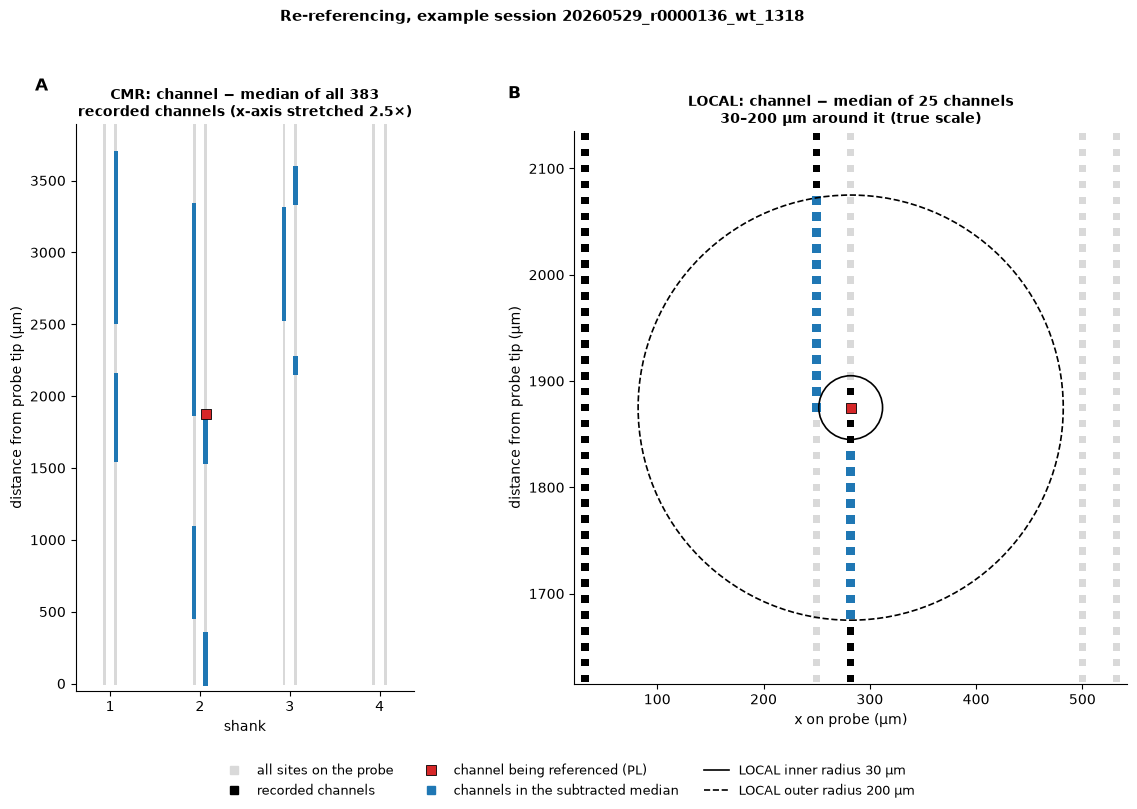

In [15]:
# %%
# ── REF-1. WHAT DO CMR AND LOCAL SUBTRACT? one session, one example channel (shank 2, both columns) ──
from matplotlib.patches import Circle, Rectangle
from matplotlib.lines import Line2D
SES = "20260529_r0000136_wt_1318"
PICK_XY = (282.0, 1875.0)                            # example channel: shank 2, column 2, 1875 µm (both columns recorded here)
R_IN, R_OUT, MIN_NB = 30.0, 200.0, 5                 # LOCAL: local_radius=(30, 200); SpikeInterface falls back to the closest 5 beyond R_IN
X_STRETCH = 2.5                                      # main panels: x drawn 2.5x wider than y (inset = true scale)
ZOOM = 260                                           # inset: ± µm around the red channel
REG_SHORT = {"Prelimbic area": "PL", "Infralimbic area": "IL", "Cingulate area 1": "Cg1",
             "Secondary motor area": "M2", "Basal forebrain region, unspecified": "BF"}

recs, removed = fn.load_session(PROC, SES, XB, refs=("original", "CMR", "LOCAL"))
orig = recs["original"]
ids = np.array([str(c) for c in orig.get_channel_ids()]); loc = orig.get_channel_locations()
k = int(np.argmin(np.hypot(loc[:, 0] - PICK_XY[0], loc[:, 1] - PICK_XY[1])))         # closest recorded channel to PICK_XY
CID = ids[k]
CHR = pd.read_csv(os.path.join(TABLES, "channel_regions_all.csv"))
REG = REG_SHORT.get(CHR.loc[(CHR["session"] == SES) & (CHR["channel_id"].astype(str) == CID), "region"].squeeze(), "?")

# neighbours of the LOCAL reference: SpikeInterface's own list if available, else the same rule recomputed
seg = recs["LOCAL"]._recording_segments[0]
nb = None
for name in ("neighbors", "local_neighbors"):
    if hasattr(seg, name):
        nb = np.asarray(getattr(seg, name)[k]); src = f"SpikeInterface ({name})"; break
if nb is None:
    d = np.linalg.norm(loc - loc[k], axis=1)
    nb = np.flatnonzero((d > R_IN) & (d <= R_OUT))
    if len(nb) < MIN_NB:
        cand = np.flatnonzero(d > R_IN); nb = cand[np.argsort(d[cand])[:MIN_NB]]
    src = "rule recomputed (30 < d ≤ 200 µm)"
print(f"{SES}: {len(ids)} channels after bad-channel removal ({len(removed)} extra bad removed) | red channel {CID} ({REG}) "
      f"at x={loc[k, 0]:.0f}, y={loc[k, 1]:.0f} µm")
print(f"CMR subtracts the median of {len(ids)} channels (all) | LOCAL subtracts the median of {len(nb)} channels ({src}); "
      f"of these, {int((np.abs(loc[nb, 0] - loc[k, 0]) > 1).sum())} are in the other column")

# check: recompute both references by hand for 1 s and compare with SpikeInterface
fs = orig.get_sampling_frequency(); a = int(orig.get_num_samples() // 2); b = a + int(fs)
X = orig.get_traces(start_frame=a, end_frame=b, return_in_uV=True).astype(float)
cmr_hand = X[:, k] - np.median(X, axis=1)
loc_hand = X[:, k] - np.median(X[:, nb], axis=1)
cmr_si = recs["CMR"].get_traces(start_frame=a, end_frame=b, channel_ids=[CID], return_in_uV=True)[:, 0]
loc_si = recs["LOCAL"].get_traces(start_frame=a, end_frame=b, channel_ids=[CID], return_in_uV=True)[:, 0]
gain = float(np.median(orig.get_channel_gains()))
print(f"check (max |by hand − SpikeInterface|): CMR {np.abs(cmr_hand - cmr_si).max():.2f} µV, "
      f"LOCAL {np.abs(loc_hand - loc_si).max():.2f} µV (1 bit = {gain:.2f} µV)")

# figure: left = CMR on the whole probe (x stretched), right = LOCAL zoomed at true scale
ALLX = np.array([sh * 250 + col for sh in range(4) for col in (0, 32)]); YMAX = loc[:, 1].max() + 200
gx, gy = np.meshgrid(ALLX, np.arange(0, 640) * 15.0)
gx, gy = gx[gy <= YMAX], gy[gy <= YMAX]

def draw_sites(ax, blue, s_bg, s_blue, s_red):
    ax.scatter(gx, gy, s=s_bg, marker="s", color="0.85", edgecolors="none", rasterized=True)
    ax.scatter(loc[:, 0], loc[:, 1], s=s_bg, marker="s", color="k", edgecolors="none", rasterized=True)
    ax.scatter(loc[blue, 0], loc[blue, 1], s=s_blue, marker="s", color="#1f77b4", edgecolors="none", rasterized=True)
    ax.scatter(loc[k, 0], loc[k, 1], s=s_red, marker="s", color="#d62728", edgecolors="k", linewidths=0.6, zorder=5)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 8), facecolor="white", gridspec_kw={"width_ratios": [1, 1.2]})

# A: CMR, whole probe
draw_sites(a1, np.arange(len(ids)), 4, 10, 60)                          # bigger red square
a1.set_aspect(1 / X_STRETCH); a1.set_xlim(-80, 3 * 250 + 112); a1.set_ylim(-50, YMAX)
a1.set_xticks([sh * 250 + 16 for sh in range(4)]); a1.set_xticklabels([str(sh + 1) for sh in range(4)]); a1.set_xlabel("shank")
a1.set_ylabel("distance from probe tip (µm)")
a1.set_title(f"CMR: channel − median of all {len(ids)}\nrecorded channels (x-axis stretched {X_STRETCH}×)", fontsize=10, fontweight="bold")

# B: LOCAL, zoom around the red channel at true scale
draw_sites(a2, nb, 30, 40, 50)
for r, ls in ((R_IN, "-"), (R_OUT, "--")):
    a2.add_patch(Circle((loc[k, 0], loc[k, 1]), r, fill=False, color="k", lw=1.2, ls=ls, zorder=6))
a2.set_xlim(loc[k, 0] - ZOOM, loc[k, 0] + ZOOM); a2.set_ylim(loc[k, 1] - ZOOM, loc[k, 1] + ZOOM)
a2.set_aspect("equal")
a2.set_xlabel("x on probe (µm)"); a2.set_ylabel("distance from probe tip (µm)")
a2.set_title(f"LOCAL: channel − median of {len(nb)} channels\n30–200 µm around it (true scale)", fontsize=10, fontweight="bold")

for ax, lab in ((a1, "A"), (a2, "B")):
    ax.text(-0.12, 1.06, lab, transform=ax.transAxes, fontsize=12, fontweight="bold")
    for sp in ("top", "right"): ax.spines[sp].set_visible(False)

handles = [Line2D([], [], marker="s", ls="", ms=6, color="0.85", label="all sites on the probe"),
           Line2D([], [], marker="s", ls="", ms=6, color="k", label="recorded channels"),
           Line2D([], [], marker="s", ls="", ms=7, color="#d62728", mec="k", mew=0.6, label=f"channel being referenced ({REG})"),
           Line2D([], [], marker="s", ls="", ms=6, color="#1f77b4", label="channels in the subtracted median"),
           Line2D([], [], color="k", ls="-", lw=1.2, label="LOCAL inner radius 30 µm"),
           Line2D([], [], color="k", ls="--", lw=1.2, label="LOCAL outer radius 200 µm")]
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False, fontsize=9)
fig.suptitle(f"Re-referencing, example session {SES}", fontsize=11, fontweight="bold", y=0.995)
fig.tight_layout(rect=(0, 0.07, 1, 0.97), w_pad=3)
PROBE_DIR = os.path.join(r"O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\amir_data", "Probe")
os.makedirs(PROBE_DIR, exist_ok=True)
fig.savefig(os.path.join(PROBE_DIR, "referencing example.pdf"), dpi=300, facecolor="white", bbox_inches="tight")
plt.show()

<div style="color:#b8860b; border-left:4px solid #b8860b; padding-left:10px">

## 5. Bursts with EXACT times (for the last-burst-to-tone analysis)
fn.bursts_session_exact: same Karvat 2021 detection, channels and artifact rule as fn.bursts_session, but saves the exact
start / end time of every beta burst and the time of every burst peak (session clock, s), plus artifact periods; CMR and LOCAL.
Output: data\analysis_main\bursts_karvat2021_exact\<session>.npz (+ _trials.csv).
Test: one session, compared with the old 50-ms bins (the occupancy rebuilt from the exact times must match the old file).

<div>

In [ ]:
# %%
# ── 5. BURSTS WITH EXACT TIMES: ALL FINAL SESSIONS (overnight) ──
importlib.reload(fn)
RUN_EXACT = True
BURST_EXACT = EXACT_DIR                                                      # amir_data\data\Bursts detection exact times (from the settings)
todo = [s for s in final["session"] if not os.path.exists(os.path.join(BURST_EXACT, s + ".npz"))]
print(f"exact bursts: {len(final) - len(todo)} done, {len(todo)} to do", flush=True)
if RUN_EXACT:
    t_all = time.time()
    for i, s in enumerate(todo, 1):
        t0 = time.time()
        try:
            recs, _ = fn.load_session(PROC, s, XB, refs=("CMR", "LOCAL"))
            rat = final.set_index("session").loc[s, "rat"]
            fn.bursts_session_exact(recs, fn.session_trials(K, s), REP, CHREG, s, rat, os.path.join(BURST_EXACT, s + ".npz"), verbose=False)
            print(f"[{i}/{len(todo)}] {s}: ok ({(time.time() - t0) / 60:.1f} min)", flush=True)
        except Exception as e:
            print(f"[{i}/{len(todo)}] {s}: ERROR {e!r}", flush=True)
            pd.DataFrame([{"session": s, "error": repr(e)}]).to_csv(os.path.join(TABLES, "bursts_exact_errors.csv"), mode="a",
                         header=not os.path.exists(os.path.join(TABLES, "bursts_exact_errors.csv")), index=False)
    print(f"exact bursts finished in {(time.time() - t_all) / 60:.0f} min", flush=True)

exact bursts: 0 done, 60 to do
[1/60] 20260510_r0000135_wt_1625: ok (1.3 min)
[2/60] 20260510_r0000136_wt_1926: ok (0.9 min)
[3/60] 20260511_r0000136_wt_0909: ok (0.2 min)
[4/60] 20260511_r0000136_wt_0930: ok (0.5 min)
[5/60] 20260511_r0000136_wt_1832: ok (0.8 min)
[6/60] 20260512_r0000136_wt_1054: ok (1.0 min)
[7/60] 20260513_r0000136_wt_1729: ok (0.3 min)
[8/60] 20260514_r0000136_wt_1317: ok (0.8 min)
[9/60] 20260515_r0000135_wt_1953: ok (1.1 min)
[10/60] 20260515_r0000135_wt_1957: ok (0.5 min)
[11/60] 20260515_r0000136_wt_1817: ok (1.2 min)
[12/60] 20260517_r0000135_wt_1846: ok (1.6 min)
[13/60] 20260517_r0000136_wt_1557: ok (1.5 min)
[14/60] 20260519_r0000136_wt_2031: ok (1.5 min)
[15/60] 20260520_r0000135_wt_1357: ok (1.0 min)
[16/60] 20260520_r0000136_wt_1443: ok (1.0 min)
[17/60] 20260521_r0000135_wt_1309: ok (1.3 min)
[18/60] 20260521_r0000136_wt_1221: ok (1.2 min)
[19/60] 20260522_r0000135_wt_1716: ok (1.4 min)
[20/60] 20260522_r0000136_wt_1750: ok (1.5 min)
[21/60] 20260523_r

In [7]:
# %%
# ── 5a. BURSTS WITH EXACT TIMES: TEST ON ONE SESSION + check against the 50-ms bins ──
importlib.reload(fn)
BURST_EXACT = EXACT_DIR                                                      # amir_data\data\Bursts detection exact times (from the settings)
recs, _ = fn.load_session(PROC, TEST, XB, refs=("CMR", "LOCAL"))
rat = final.set_index("session").loc[TEST, "rat"]
t0 = time.time()
ze = fn.bursts_session_exact(recs, fn.session_trials(K, TEST), REP, CHREG, TEST, rat, os.path.join(BURST_EXACT, TEST + ".npz"))
print(f"done in {(time.time() - t0) / 60:.1f} min")

# check: rebuild the 50-ms occupancy around the tone from the exact times and compare with the 50-ms file
zo = np.load(os.path.join(BURST_DIR, TEST + ".npz")); T = pd.read_csv(os.path.join(BURST_DIR, TEST + "_trials.csv"))
col, a, zz = fn.BURST_ALIGN["tone"]; nb = int(round((zz - a) / fn.BURST_BIN))
for ref in ("CMR", "LOCAL"):
    for reg in ("PL", "IL", "Cg1"):
        k = f"{ref}|beta 15-30|{reg}"
        if k + "|burst_start_s" not in ze:
            continue
        bs, be, old = ze[k + "|burst_start_s"], ze[k + "|burst_end_s"], zo[k + "|tone|occ"]
        diffs = []
        for i, t in enumerate(T[col].values):
            if not np.isfinite(t) or not np.isfinite(old[i]).all():
                continue
            lo = t + a + np.arange(nb) * fn.BURST_BIN; hi = lo + fn.BURST_BIN
            ov = np.clip(np.minimum(be[None, :], hi[:, None]) - np.maximum(bs[None, :], lo[:, None]), 0, None).sum(1) / fn.BURST_BIN
            diffs.append(np.abs(ov - old[i]).max())
        print(f"{ref} {reg}: {len(bs)} bursts | rebuilt vs 50-ms occupancy: max difference {max(diffs):.4f} (should be ~0)")

    CMR Cg1 beta 15-30: 3984 bursts, occupancy 0.253 (9 s)
    CMR IL beta 15-30: 4270 bursts, occupancy 0.268 (13 s)
    CMR PL beta 15-30: 4316 bursts, occupancy 0.269 (16 s)
    LOCAL Cg1 beta 15-30: 3636 bursts, occupancy 0.251 (22 s)
    LOCAL IL beta 15-30: 4424 bursts, occupancy 0.274 (26 s)
    LOCAL PL beta 15-30: 4281 bursts, occupancy 0.270 (29 s)
done in 0.5 min
CMR PL: 4316 bursts | rebuilt vs 50-ms occupancy: max difference 0.0100 (should be ~0)
CMR IL: 4270 bursts | rebuilt vs 50-ms occupancy: max difference 0.0100 (should be ~0)
CMR Cg1: 3984 bursts | rebuilt vs 50-ms occupancy: max difference 0.0100 (should be ~0)
LOCAL PL: 4281 bursts | rebuilt vs 50-ms occupancy: max difference 0.0100 (should be ~0)
LOCAL IL: 4424 bursts | rebuilt vs 50-ms occupancy: max difference 0.0100 (should be ~0)
LOCAL Cg1: 3636 bursts | rebuilt vs 50-ms occupancy: max difference 0.0100 (should be ~0)


<div style="color:#b8860b; border-left:4px solid #b8860b; padding-left:10px">

### 5c. Burst properties and burst waveforms (for Golan / Karvat 2020 Fig. 2 and Fig. 4)

Same detection as the exact-time bursts (karvat_bursts, LOCAL, representative IL channel, artifact rule, 90th percentile), run again to keep,
for every burst peak: peak frequency, peak power (× threshold), frequency span, and duration at the peak frequency.
For the burst averages: each burst is aligned to the nearest trough of the 15–30 Hz filtered LFP and ±0.5 s of raw LFP is cut;
saved per session as the mean of all bursts and of the 50 strongest (plus single examples for the test session).
Output: <i>amir_data / data / Burst properties</i>, one .npz per session.
<div>

In [10]:
# %%
# ── 5c. BURST PROPERTIES + TROUGH-ALIGNED WAVEFORMS (IL, LOCAL, beta) — for Karvat 2020 Fig. 2 and Fig. 4 ──
import scipy.signal as ss
from skimage.morphology import local_maxima
importlib.reload(fn)
ONLY_TEST, OVERWRITE = False, False                                   # True: test session only (check first); then False for all sessions
REG, REF, BAND = "IL", "LOCAL", "beta 15-30"
PROP_DIR = os.path.join(DATA_OUT, "Burst properties"); os.makedirs(PROP_DIR, exist_ok=True)
HALF_S, N_TOP, N_EX = 0.5, 50, 100                                    # ±0.5 s snippets, 50 strongest, 100 random examples (test session)

def burst_properties(x, fs, art):
    """karvat_bursts steps, but returns per peak: sample, frequency, power (x threshold), span (Hz), duration (s, at the peak frequency)"""
    cfg = fn.BURST_BANDS[BAND]; band, ncyc = cfg["range"], cfg["n_cycles"]
    foi = np.arange(max(1, band[0] - 1), band[1] + 2)
    P = np.empty((len(foi), len(x)), np.float32)
    for i, f in enumerate(foi):
        P[i] = np.abs(ss.fftconvolve(x, fn.morlet(f, ncyc, fs), mode="same")) ** 2
    P[:, art] = np.nan
    with np.errstate(invalid="ignore", divide="ignore"):
        M = P / np.nanpercentile(P, fn.BURST_PCT, axis=1, keepdims=True)
    del P
    M[~(M >= 1)] = 0
    pk = local_maxima(M, connectivity=2, allow_borders=True) & (M > 0); pk[[0, -1], :] = False
    rows = []
    for i in range(1, len(foi) - 1):
        js = np.flatnonzero(pk[i])
        if not len(js): continue
        row = M[i] > 0
        d = np.diff(np.concatenate([[0], row.astype(np.int8), [0]])); st, en = np.flatnonzero(d == 1), np.flatnonzero(d == -1)
        k = np.searchsorted(st, js, "right") - 1                    # run (at this frequency) that contains each peak
        for j, kk in zip(js, k):
            col = M[:, j] > 0; lo = hi = i                           # frequency span: contiguous rows above threshold at the peak time
            while lo - 1 >= 0 and col[lo - 1]: lo -= 1
            while hi + 1 < len(foi) and col[hi + 1]: hi += 1
            rows.append((j, foi[i], M[i, j], foi[hi] - foi[lo], (en[kk] - st[kk]) / fs))
    rows.sort()
    return np.array(rows, dtype=float).reshape(-1, 5)

todo = [TEST] if ONLY_TEST else [s for s in final["session"] if OVERWRITE or not os.path.exists(os.path.join(PROP_DIR, s + ".npz"))]
print(f"burst properties: {len(todo)} session(s) to do -> {PROP_DIR}", flush=True)
t_all = time.time()
for n_, s in enumerate(todo, 1):
    t0 = time.time()
    try:
        recs, _ = fn.load_session(PROC, s, XB, refs=(REF,)); rec = recs[REF]; fs = rec.get_sampling_frequency()
        rat = final.set_index("session").loc[s, "rat"]
        pick, _ = fn.pick_region_channels(rec, s, REP, CHREG, rat)
        if REG not in pick: print(f"[{n_}/{len(todo)}] {s}: no {REG} channel"); continue
        x = fn.read_full(rec, [pick[REG]])[:, 0]
        art = fn._ndi_dilate(np.abs(x) > fn.BURST_ART_UV, fn.BURST_ART_PAD)
        PR = burst_properties(x, fs, art)                              # columns: sample, freq, power, span, duration
        # check against the exact-time file (same peaks?)
        ze = np.load(os.path.join(EXACT_DIR, s + ".npz")); old = ze[f"{REF}|{BAND}|{REG}|peak_s"]
        match = np.isin(np.round(PR[:, 0]).astype(int), np.round(old * fs).astype(int)).mean() if len(PR) else np.nan
        # trough-aligned waveforms (raw LOCAL LFP, ±0.5 s)
        sos = ss.butter(4, [15, 30], btype="bandpass", fs=fs, output="sos"); xf = ss.sosfiltfilt(sos, np.where(art, 0, x))
        tr = ss.find_peaks(-xf)[0]; h = int(round(HALF_S * fs)); W, keep = [], []
        for q, (j, f) in enumerate(PR[:, :2]):
            j = int(j); w_ = int(round(fs / (2 * f)))                 # nearest trough within half a period of the peak frequency
            c = tr[(tr >= j - w_) & (tr <= j + w_)]
            if not len(c): continue
            t_ = c[np.argmin(np.abs(c - j))]
            if t_ - h < 0 or t_ + h >= len(x) or art[t_ - h:t_ + h + 1].any(): continue
            W.append(x[t_ - h:t_ + h + 1]); keep.append(q)
        W = np.asarray(W, np.float32); keep = np.asarray(keep)
        top = np.argsort(PR[keep, 2])[::-1][:N_TOP] if len(keep) else np.array([], int)
        out = dict(peak_s=PR[:, 0] / fs, peak_hz=PR[:, 1], power_x_thr=PR[:, 2], span_hz=PR[:, 3], dur_s=PR[:, 4], fs=np.array([fs]),
                   channel=np.array([pick[REG]]), task_start_s=np.array([np.nanmin(fn.session_trials(K, s)["press_s"])]),
                   task_end_s=np.array([np.nanmax(fn.session_trials(K, s)["release_s"])]),
                   wave_t=np.arange(-h, h + 1) / fs, wave_mean_all=W.mean(0) if len(W) else np.array([]), wave_n_all=np.array([len(W)]),
                   wave_mean_top=W[top].mean(0) if len(top) else np.array([]), wave_keep_idx=keep)
        if s == TEST and len(W):
            rng = np.random.default_rng(0)
            out["wave_top"] = W[top]; out["wave_random"] = W[rng.choice(len(W), min(N_EX, len(W)), replace=False)]
        np.savez_compressed(os.path.join(PROP_DIR, s + ".npz"), **out)
        print(f"[{n_}/{len(todo)}] {s}: {len(PR)} peaks (match with exact file {100 * match:.1f} %), {len(W)} waveforms | "
              f"median freq {np.median(PR[:, 1]):.0f} Hz, span {np.median(PR[:, 3]):.0f} Hz, duration {1000 * np.median(PR[:, 4]):.0f} ms, "
              f"power {np.median(PR[:, 2]):.2f}× thr | fs {fs:.0f} Hz | {(time.time() - t0) / 60:.1f} min", flush=True)
        del x, recs
    except Exception as e:
        print(f"[{n_}/{len(todo)}] {s}: ERROR {e!r}", flush=True)
print(f"finished in {(time.time() - t_all) / 60:.0f} min")

burst properties: 59 session(s) to do -> O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\amir_data\data\Burst properties
[1/59] 20260510_r0000135_wt_1625: 10225 peaks (match with exact file 100.0 %), 9935 waveforms | median freq 22 Hz, span 5 Hz, duration 97 ms, power 1.52× thr | fs 1000 Hz | 1.0 min
[2/59] 20260510_r0000136_wt_1926: 7559 peaks (match with exact file 100.0 %), 7384 waveforms | median freq 22 Hz, span 4 Hz, duration 93 ms, power 1.45× thr | fs 1000 Hz | 0.6 min
[3/59] 20260511_r0000136_wt_0909: 1722 peaks (match with exact file 100.0 %), 1678 waveforms | median freq 22 Hz, span 5 Hz, duration 96 ms, power 1.50× thr | fs 1000 Hz | 0.2 min
[4/59] 20260511_r0000136_wt_0930: 4583 peaks (match with exact file 100.0 %), 4471 waveforms | median freq 23 Hz, span 4 Hz, duration 93 ms, power 1.44× thr | fs 1000 Hz | 0.4 min
[5/59] 20260511_r0000136_wt_1832: 6426 peaks (match with exact file 100.0 %), 6286 waveforms | median freq 22 Hz, span 4 Hz, duration 94 ms, power 1.4

<div style="color:#b8860b; border-left:4px solid #b8860b; padding-left:10px">

### 5d. Burst properties at the 98th percentile (Karvat 2020) and 90th percentile, with power × median

Same as 5c (IL, LOCAL, beta 15–30 Hz, same Morlet / artifact rule), run with the 98th-percentile threshold used in Karvat et al. 2020
(and again with the 90th percentile used in all our analyses). New per burst peak: power relative to the median of that frequency (FOM, as Karvat 2020 Fig. 2e);
also saved: burst start / end times at that threshold, and trough-aligned waveforms.
Output: <i>amir_data / data / Burst properties p98</i> and <i>… / Burst properties p90</i>, one .npz per session.
<div>

In [11]:
# %%
# ── 5d. BURST PROPERTIES AT THE 98th (Karvat 2020) AND 90th PERCENTILE, with power × median (FOM) — overnight (IL, LOCAL, beta) ──
import scipy.signal as ss
from skimage.morphology import local_maxima
importlib.reload(fn)
PCTS, ONLY_TEST, OVERWRITE = (98, 90), False, False                  # thresholds to run; ONLY_TEST=True runs the test session only
REG, REF, BAND = "IL", "LOCAL", "beta 15-30"
HALF_S, N_TOP, N_EX = 0.5, 50, 100

def burst_properties_pct(x, fs, art, pct):
    """karvat_bursts steps at percentile pct; per peak: sample, freq, power x threshold, power x median, span (Hz), duration (s);
       plus burst-on mask (runs at the peak frequency that contain a peak, as karvat_bursts)"""
    cfg = fn.BURST_BANDS[BAND]; band, ncyc = cfg["range"], cfg["n_cycles"]
    foi = np.arange(max(1, band[0] - 1), band[1] + 2)
    P = np.empty((len(foi), len(x)), np.float32)
    for i, f in enumerate(foi):
        P[i] = np.abs(ss.fftconvolve(x, fn.morlet(f, ncyc, fs), mode="same")) ** 2
    P[:, art] = np.nan
    thr = np.nanpercentile(P, pct, axis=1, keepdims=True); med = np.nanmedian(P, axis=1, keepdims=True)
    with np.errstate(invalid="ignore", divide="ignore"):
        M = P / thr
    thr_over_med = (thr / med)[:, 0]                                  # power × median = (power × threshold) × (threshold / median)
    del P
    M[~(M >= 1)] = 0
    pk = local_maxima(M, connectivity=2, allow_borders=True) & (M > 0); pk[[0, -1], :] = False
    on = np.zeros(len(x), bool); rows = []
    for i in range(1, len(foi) - 1):
        js = np.flatnonzero(pk[i])
        if not len(js): continue
        row = M[i] > 0
        d = np.diff(np.concatenate([[0], row.astype(np.int8), [0]])); st, en = np.flatnonzero(d == 1), np.flatnonzero(d == -1)
        run = np.cumsum(np.diff(np.concatenate([[0], row.astype(np.int8)])) == 1)
        on |= np.isin(run, np.unique(run[js])) & row
        k = np.searchsorted(st, js, "right") - 1
        for j, kk in zip(js, k):
            col = M[:, j] > 0; lo = hi = i
            while lo - 1 >= 0 and col[lo - 1]: lo -= 1
            while hi + 1 < len(foi) and col[hi + 1]: hi += 1
            rows.append((j, foi[i], M[i, j], M[i, j] * thr_over_med[i], foi[hi] - foi[lo], (en[kk] - st[kk]) / fs))
    rows.sort()
    return np.array(rows, dtype=float).reshape(-1, 6), on

sessions = [TEST] if ONLY_TEST else list(final["session"])
t_all = time.time()
for pct in PCTS:
    OUTD = os.path.join(DATA_OUT, f"Burst properties p{pct}"); os.makedirs(OUTD, exist_ok=True)
    todo = [s for s in sessions if OVERWRITE or not os.path.exists(os.path.join(OUTD, s + ".npz"))]
    print(f"\n=== {pct}th percentile: {len(todo)} session(s) to do -> {OUTD}", flush=True)
    for n_, s in enumerate(todo, 1):
        t0 = time.time()
        try:
            recs, _ = fn.load_session(PROC, s, XB, refs=(REF,)); rec = recs[REF]; fs = rec.get_sampling_frequency()
            rat = final.set_index("session").loc[s, "rat"]
            pick, _ = fn.pick_region_channels(rec, s, REP, CHREG, rat)
            if REG not in pick: print(f"[{n_}/{len(todo)}] {s}: no {REG} channel"); continue
            x = fn.read_full(rec, [pick[REG]])[:, 0]
            art = fn._ndi_dilate(np.abs(x) > fn.BURST_ART_UV, fn.BURST_ART_PAD)
            PR, on = burst_properties_pct(x, fs, art, pct)                # sample, freq, power×thr, power×median, span, duration
            bstart, bend = fn._runs(on, fs)
            # trough-aligned waveforms (raw LOCAL LFP, ±0.5 s)
            sos = ss.butter(4, [15, 30], btype="bandpass", fs=fs, output="sos"); xf = ss.sosfiltfilt(sos, np.where(art, 0, x))
            tr = ss.find_peaks(-xf)[0]; h = int(round(HALF_S * fs)); W, keep = [], []
            for q, (j, f) in enumerate(PR[:, :2]):
                j = int(j); w_ = int(round(fs / (2 * f))); c = tr[(tr >= j - w_) & (tr <= j + w_)]
                if not len(c): continue
                t_ = c[np.argmin(np.abs(c - j))]
                if t_ - h < 0 or t_ + h >= len(x) or art[t_ - h:t_ + h + 1].any(): continue
                W.append(x[t_ - h:t_ + h + 1]); keep.append(q)
            W = np.asarray(W, np.float32); keep = np.asarray(keep)
            top = np.argsort(PR[keep, 2])[::-1][:N_TOP] if len(keep) else np.array([], int)
            ST_ = fn.session_trials(K, s)
            out = dict(pct=np.array([pct]), peak_s=PR[:, 0] / fs, peak_hz=PR[:, 1], power_x_thr=PR[:, 2], power_x_median=PR[:, 3],
                       span_hz=PR[:, 4], dur_s=PR[:, 5], burst_start_s=bstart, burst_end_s=bend,
                       art_start_s=fn._runs(art, fs)[0], art_end_s=fn._runs(art, fs)[1], fs=np.array([fs]), channel=np.array([pick[REG]]),
                       task_start_s=np.array([np.nanmin(ST_["press_s"])]), task_end_s=np.array([np.nanmax(ST_["release_s"])]),
                       wave_t=np.arange(-h, h + 1) / fs, wave_mean_all=W.mean(0) if len(W) else np.array([]), wave_n_all=np.array([len(W)]),
                       wave_mean_top=W[top].mean(0) if len(top) else np.array([]), wave_keep_idx=keep)
            if s == TEST and len(W):
                rng = np.random.default_rng(0)
                out["wave_top"] = W[top]; out["wave_random"] = W[rng.choice(len(W), min(N_EX, len(W)), replace=False)]
            np.savez_compressed(os.path.join(OUTD, s + ".npz"), **out)
            print(f"[{pct}th {n_}/{len(todo)}] {s}: {len(PR)} peaks, {len(bstart)} bursts | median freq {np.median(PR[:, 1]):.0f} Hz, "
                  f"span {np.median(PR[:, 4]):.0f} Hz, duration {1000 * np.median(PR[:, 5]):.0f} ms, power {np.median(PR[:, 3]):.1f}× median | "
                  f"{(time.time() - t0) / 60:.1f} min", flush=True)
            del x, recs
        except Exception as e:
            print(f"[{pct}th {n_}/{len(todo)}] {s}: ERROR {e!r}", flush=True)
print(f"\nall done in {(time.time() - t_all) / 60:.0f} min")


=== 98th percentile: 60 session(s) to do -> O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\amir_data\data\Burst properties p98
[98th 1/60] 20260510_r0000135_wt_1625: 3041 peaks, 2307 bursts | median freq 23 Hz, span 3 Hz, duration 72 ms, power 9.0× median | 1.0 min
[98th 2/60] 20260510_r0000136_wt_1926: 2423 peaks, 1931 bursts | median freq 23 Hz, span 3 Hz, duration 66 ms, power 7.2× median | 0.6 min
[98th 3/60] 20260511_r0000136_wt_0909: 607 peaks, 485 bursts | median freq 23 Hz, span 3 Hz, duration 63 ms, power 6.9× median | 0.2 min
[98th 4/60] 20260511_r0000136_wt_0930: 1471 peaks, 1196 bursts | median freq 22 Hz, span 3 Hz, duration 66 ms, power 7.0× median | 0.4 min
[98th 5/60] 20260511_r0000136_wt_1832: 2132 peaks, 1689 bursts | median freq 22 Hz, span 3 Hz, duration 65 ms, power 7.0× median | 0.5 min
[98th 6/60] 20260512_r0000136_wt_1054: 2650 peaks, 2126 bursts | median freq 22 Hz, span 3 Hz, duration 65 ms, power 7.1× median | 0.7 min
[98th 7/60] 20260513_r0000136_w

<div style="color:#b8860b; border-left:4px solid #b8860b; padding-left:10px">

### 5e. Average IL beta burst per session (LOCAL, 98th percentile) — data for 07 Step 9 (independent cell)
Runs on its own (loads paths, functions and bad channels itself). Uses the burst files of 5d ("Burst properties p98").
Per session: bursts as in 07 Step 8 (strongest peak of each merged burst, task period); aligned to the beta trough (15–30 Hz, nearest the peak), ±300 ms,
bursts touching an artifact excluded. Mean of the <b>selected</b> bursts (≥ 70 ms and peak 20–25 Hz, Karvat 2020) and of <b>all</b> bursts;
10 random selected single traces with their above-threshold mask.
Numbers per mean: trough depth (µV, vs baseline |t| > 200 ms), oscillation length (15–30 Hz envelope above half its maximum; ms and cycles at 22.5 Hz),
clarity (trough depth / baseline SD); plus beta share of the raw signal (15–30 / 1–200 Hz).
Output: amir_data\data\Burst averages p98 LOCAL\ (one .npz per session + burst_average_metrics.csv). Skips sessions already done.
<div>

In [1]:
# ── 5e. AVERAGE IL BETA BURST PER SESSION (LOCAL, 98th percentile) — INDEPENDENT CELL (data for 07 Step 9) ──
import os, sys, glob, time, importlib, warnings
import numpy as np, pandas as pd
import scipy.signal as ss
MAIN = r"C:\Users\ar687\Documents\GitHub\AmirAnalysis\main"
sys.path.insert(0, MAIN)
import functions as fn
importlib.reload(fn)
warnings.filterwarnings("ignore", message="The following channels did not have enough neighbors")
warnings.filterwarnings("ignore", message="Mean of empty slice|All-NaN slice")

DATA_ROOT = r"O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data"
DATA_OUT  = os.path.join(DATA_ROOT, "amir_data", "data")
PROC      = os.path.join(DATA_ROOT, "2_processed")
TABLES    = os.path.join(MAIN, "tables")
XB        = pd.read_csv(os.path.join(TABLES, "extra_bad_channels.csv"))
PROP_DIR  = os.path.join(DATA_OUT, "Burst properties p98")
AVG_DIR   = os.path.join(DATA_OUT, "Burst averages p98 LOCAL"); os.makedirs(AVG_DIR, exist_ok=True)

REF, HALF, BASE = "LOCAL", 0.30, 0.20                                # ±window (s); baseline = |t| > BASE
MIN_DUR, BAND, F_MID = 0.070, (20, 25), 22.5                         # Karvat selection; middle of the band for "cycles"
N_TR, OVERWRITE = 10, False

def align(x, fs, art, P, h, tr):
    """trough nearest each burst peak (as 5d) -> sample indices of the aligned troughs (no artifact in ±h)"""
    K_ = []
    for t, f in zip(P.t.values, P.f.values):
        j = int(round(t * fs)); w_ = int(round(fs / (2 * f))); c = tr[(tr >= j - w_) & (tr <= j + w_)]
        if not len(c): continue
        k = c[np.argmin(np.abs(c - j))]
        if k - h >= 0 and k + h < len(x) and not art[k - h:k + h + 1].any(): K_.append(k)
    return np.array(K_, int)

def metrics(m, tsec, fs):
    """trough depth (µV), oscillation length (envelope above half max around 0; ms and cycles), clarity (depth / baseline SD)"""
    c = len(m) // 2; bl = np.abs(tsec) > BASE
    depth = m[c] - np.median(m[bl])
    env = np.abs(ss.hilbert(ss.sosfiltfilt(ss.butter(4, [15, 30], btype="bandpass", fs=fs, output="sos"), m - np.median(m[bl]))))
    above = env >= 0.5 * env[np.abs(tsec) <= 0.05].max()
    lo = c; hi = c
    while lo > 0 and above[lo - 1]: lo -= 1
    while hi < len(m) - 1 and above[hi + 1]: hi += 1
    width_ms = 1000 * (hi - lo + 1) / fs
    return depth, width_ms, width_ms / 1000 * F_MID, abs(depth) / np.std(m[bl])

sessions = sorted(os.path.basename(f)[:-4] for f in glob.glob(os.path.join(PROP_DIR, "*.npz")))
todo = [s for s in sessions if OVERWRITE or not os.path.exists(os.path.join(AVG_DIR, s + ".npz"))]
print(f"{len(sessions)} sessions, {len(todo)} to do -> {AVG_DIR}", flush=True)
t_start = time.time()
for n_, s in enumerate(todo, 1):
    t_s = time.time()
    try:
        z = np.load(os.path.join(PROP_DIR, s + ".npz")); ch = str(z["channel"][0])
        recs, _ = fn.load_session(PROC, s, XB, refs=(REF,)); fs = recs[REF].get_sampling_frequency()
        x = fn.read_full(recs[REF], [ch])[:, 0]; n = len(x)
        art = np.zeros(n, bool)
        for a, b in zip(z["art_start_s"], z["art_end_s"]): art[int(a * fs):int(np.ceil(b * fs)) + 1] = True
        on = np.zeros(n, bool)
        for a, b in zip(z["burst_start_s"], z["burst_end_s"]): on[int(a * fs):int(np.ceil(b * fs)) + 1] = True
        # bursts as in 07 Step 8: strongest peak of each merged burst, task period
        t0, t1 = float(z["task_start_s"][0]), float(z["task_end_s"][0])
        P = pd.DataFrame(dict(t=z["peak_s"], f=z["peak_hz"], d=z["dur_s"], p=z["power_x_median"])); P = P[(P.t >= t0) & (P.t <= t1)]
        bs, be = z["burst_start_s"], z["burst_end_s"]; i = np.searchsorted(bs, P.t.values, "right") - 1
        ok = (i >= 0) & (P.t.values <= be[np.clip(i, 0, None)])
        P = P[ok].assign(b=i[ok]).sort_values("p").groupby("b").last().sort_values("t")
        Psel = P[(P.d >= MIN_DUR) & P.f.between(*BAND)]
        # trough alignment
        xf = ss.sosfiltfilt(ss.butter(4, [15, 30], btype="bandpass", fs=fs, output="sos"), np.where(art, 0, x))
        tr = ss.find_peaks(-xf)[0]; h = int(round(HALF * fs)); tsec = np.arange(-h, h + 1) / fs
        Kall, Ksel = align(x, fs, art, P, h, tr), align(x, fs, art, Psel, h, tr)
        m_all = np.mean([x[k - h:k + h + 1] for k in Kall], 0)
        m_sel = np.mean([x[k - h:k + h + 1] for k in Ksel], 0)
        pick = np.sort(np.random.default_rng(0).choice(len(Ksel), min(N_TR, len(Ksel)), replace=False))
        tr_sel = np.array([x[Ksel[q] - h:Ksel[q] + h + 1] for q in pick], np.float32)
        on_sel = np.array([on[Ksel[q] - h:Ksel[q] + h + 1] for q in pick])
        # beta share of the raw signal
        f_, pxx = ss.welch(np.where(art, 0, x), fs=fs, nperseg=int(2 * fs))
        beta_pct = 100 * pxx[(f_ >= 15) & (f_ <= 30)].sum() / pxx[(f_ >= 1) & (f_ <= 200)].sum()
        d_s, w_s, c_s, q_s = metrics(m_sel, tsec, fs); d_a, w_a, c_a, q_a = metrics(m_all, tsec, fs)
        np.savez_compressed(os.path.join(AVG_DIR, s + ".npz"), t_s=tsec, fs=np.array([fs]), channel=np.array([ch]),
                            mean_sel=m_sel, mean_all=m_all, n_sel=np.array([len(Ksel)]), n_all=np.array([len(Kall)]),
                            traces_sel=tr_sel, on_sel=on_sel, raw_rms_uV=np.array([np.std(x[~art])]), beta_pct=np.array([beta_pct]),
                            sel_depth_uV=np.array([d_s]), sel_width_ms=np.array([w_s]), sel_cycles=np.array([c_s]), sel_clarity=np.array([q_s]),
                            all_depth_uV=np.array([d_a]), all_width_ms=np.array([w_a]), all_cycles=np.array([c_a]), all_clarity=np.array([q_a]),
                            task_min=np.array([(t1 - t0) / 60]))
        done_min = (time.time() - t_start) / 60
        print(f"[{n_}/{len(todo)}] {s}: {len(Ksel)} selected / {len(Kall)} all | selected mean: trough {d_s:.1f} µV, "
              f"{w_s:.0f} ms ({c_s:.1f} cycles), clarity {q_s:.1f} | {(time.time() - t_s) / 60:.1f} min, "
              f"~{done_min / n_ * (len(todo) - n_):.0f} min left", flush=True)
        del x, recs
    except Exception as e:
        print(f"[{n_}/{len(todo)}] {s}: ERROR {e!r}", flush=True)

# ── summary table (all sessions) ──
rows = []
for s in sessions:
    f = os.path.join(AVG_DIR, s + ".npz")
    if not os.path.exists(f): continue
    z = np.load(f)
    rows.append(dict(session=s, rat=s.split("_r0000")[1][:3], n_sel=int(z["n_sel"][0]), n_all=int(z["n_all"][0]),
                     sel_per_30min=30 * int(z["n_sel"][0]) / float(z["task_min"][0]),
                     **{k: float(z[k][0]) for k in ("sel_depth_uV", "sel_width_ms", "sel_cycles", "sel_clarity",
                                                    "all_depth_uV", "all_width_ms", "all_cycles", "all_clarity", "raw_rms_uV", "beta_pct")}))
M = pd.DataFrame(rows); M.to_csv(os.path.join(AVG_DIR, "burst_average_metrics.csv"), index=False)
pd.set_option("display.width", 250)
print(f"\n{len(M)} sessions in {(time.time() - t_start) / 60:.0f} min | saved: burst_average_metrics.csv")
print("\nmedian (min–max) over sessions:")
for c in ("sel_depth_uV", "sel_width_ms", "sel_cycles", "sel_clarity", "all_depth_uV", "all_width_ms", "all_cycles", "all_clarity", "raw_rms_uV", "beta_pct"):
    print(f"   {c:14s} {M[c].median():7.2f}   ({M[c].min():.2f} – {M[c].max():.2f})")
print("\nper rat (median):"); print(M.groupby("rat")[["sel_depth_uV", "sel_width_ms", "sel_cycles", "sel_clarity", "beta_pct"]].median().round(2).to_string())

60 sessions, 60 to do -> O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\amir_data\data\Burst averages p98 LOCAL
[1/60] 20260510_r0000135_wt_1625: 416 selected / 2240 all | selected mean: trough -17.1 µV, 113 ms (2.5 cycles), clarity 28.2 | 0.9 min, ~55 min left
[2/60] 20260510_r0000136_wt_1926: 298 selected / 1811 all | selected mean: trough -10.8 µV, 115 ms (2.6 cycles), clarity 17.6 | 0.6 min, ~44 min left
[3/60] 20260511_r0000136_wt_0909: 64 selected / 414 all | selected mean: trough -11.0 µV, 116 ms (2.6 cycles), clarity 7.5 | 0.1 min, ~31 min left
[4/60] 20260511_r0000136_wt_0930: 204 selected / 1132 all | selected mean: trough -12.1 µV, 115 ms (2.6 cycles), clarity 14.8 | 0.4 min, ~28 min left
[5/60] 20260511_r0000136_wt_1832: 286 selected / 1609 all | selected mean: trough -11.0 µV, 115 ms (2.6 cycles), clarity 18.3 | 0.5 min, ~27 min left
[6/60] 20260512_r0000136_wt_1054: 331 selected / 2002 all | selected mean: trough -9.0 µV, 116 ms (2.6 cycles), clarity 22.4 | 0.6 m

<div style="color:#b8860b; border-left:4px solid #b8860b; padding-left:10px">

### 5f. As 5e, but bursts selected in the whole band (≥ 70 ms, peak 15–30 Hz) — independent cell
Same as 5e except the frequency selection (15–30 Hz instead of 20–25 Hz). Runs on its own (loads paths, functions and bad channels itself).
Output: amir_data\data\Burst averages p98 LOCAL 15-30\ (one .npz per session + burst_average_metrics.csv). Skips sessions already done.
Used in 07 to check whether Steps 9 and 10 look the same with the whole band.
<div>

In [2]:
# ── 5f. AVERAGE IL BETA BURST PER SESSION, WHOLE BAND 15–30 Hz (LOCAL, 98th percentile) — INDEPENDENT CELL ──
import os, sys, glob, time, importlib, warnings
import numpy as np, pandas as pd
import scipy.signal as ss
MAIN = r"C:\Users\ar687\Documents\GitHub\AmirAnalysis\main"
sys.path.insert(0, MAIN)
import functions as fn
importlib.reload(fn)
warnings.filterwarnings("ignore", message="The following channels did not have enough neighbors")
warnings.filterwarnings("ignore", message="Mean of empty slice|All-NaN slice")

DATA_ROOT = r"O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data"
DATA_OUT  = os.path.join(DATA_ROOT, "amir_data", "data")
PROC      = os.path.join(DATA_ROOT, "2_processed")
TABLES    = os.path.join(MAIN, "tables")
XB        = pd.read_csv(os.path.join(TABLES, "extra_bad_channels.csv"))
PROP_DIR  = os.path.join(DATA_OUT, "Burst properties p98")
AVG_DIR   = os.path.join(DATA_OUT, "Burst averages p98 LOCAL 15-30"); os.makedirs(AVG_DIR, exist_ok=True)

REF, HALF, BASE = "LOCAL", 0.30, 0.20                                # ±window (s); baseline = |t| > BASE
MIN_DUR, BAND, F_MID = 0.070, (15, 30), 22.5                         # whole band; >= 70 ms; middle of the band for "cycles"
N_TR, OVERWRITE = 10, False

def align(x, fs, art, P, h, tr):
    """trough nearest each burst peak (as 5d) -> sample indices of the aligned troughs (no artifact in ±h)"""
    K_ = []
    for t, f in zip(P.t.values, P.f.values):
        j = int(round(t * fs)); w_ = int(round(fs / (2 * f))); c = tr[(tr >= j - w_) & (tr <= j + w_)]
        if not len(c): continue
        k = c[np.argmin(np.abs(c - j))]
        if k - h >= 0 and k + h < len(x) and not art[k - h:k + h + 1].any(): K_.append(k)
    return np.array(K_, int)

def metrics(m, tsec, fs):
    """trough depth (µV), oscillation length (envelope above half max around 0; ms and cycles), clarity (depth / baseline SD)"""
    c = len(m) // 2; bl = np.abs(tsec) > BASE
    depth = m[c] - np.median(m[bl])
    env = np.abs(ss.hilbert(ss.sosfiltfilt(ss.butter(4, [15, 30], btype="bandpass", fs=fs, output="sos"), m - np.median(m[bl]))))
    above = env >= 0.5 * env[np.abs(tsec) <= 0.05].max()
    lo = c; hi = c
    while lo > 0 and above[lo - 1]: lo -= 1
    while hi < len(m) - 1 and above[hi + 1]: hi += 1
    width_ms = 1000 * (hi - lo + 1) / fs
    return depth, width_ms, width_ms / 1000 * F_MID, abs(depth) / np.std(m[bl])

sessions = sorted(os.path.basename(f)[:-4] for f in glob.glob(os.path.join(PROP_DIR, "*.npz")))
todo = [s for s in sessions if OVERWRITE or not os.path.exists(os.path.join(AVG_DIR, s + ".npz"))]
print(f"{len(sessions)} sessions, {len(todo)} to do -> {AVG_DIR}", flush=True)
t_start = time.time()
for n_, s in enumerate(todo, 1):
    t_s = time.time()
    try:
        z = np.load(os.path.join(PROP_DIR, s + ".npz")); ch = str(z["channel"][0])
        recs, _ = fn.load_session(PROC, s, XB, refs=(REF,)); fs = recs[REF].get_sampling_frequency()
        x = fn.read_full(recs[REF], [ch])[:, 0]; n = len(x)
        art = np.zeros(n, bool)
        for a, b in zip(z["art_start_s"], z["art_end_s"]): art[int(a * fs):int(np.ceil(b * fs)) + 1] = True
        on = np.zeros(n, bool)
        for a, b in zip(z["burst_start_s"], z["burst_end_s"]): on[int(a * fs):int(np.ceil(b * fs)) + 1] = True
        # bursts as in 07 Step 8: strongest peak of each merged burst, task period
        t0, t1 = float(z["task_start_s"][0]), float(z["task_end_s"][0])
        P = pd.DataFrame(dict(t=z["peak_s"], f=z["peak_hz"], d=z["dur_s"], p=z["power_x_median"])); P = P[(P.t >= t0) & (P.t <= t1)]
        bs, be = z["burst_start_s"], z["burst_end_s"]; i = np.searchsorted(bs, P.t.values, "right") - 1
        ok = (i >= 0) & (P.t.values <= be[np.clip(i, 0, None)])
        P = P[ok].assign(b=i[ok]).sort_values("p").groupby("b").last().sort_values("t")
        Psel = P[(P.d >= MIN_DUR) & P.f.between(*BAND)]
        # trough alignment
        xf = ss.sosfiltfilt(ss.butter(4, [15, 30], btype="bandpass", fs=fs, output="sos"), np.where(art, 0, x))
        tr = ss.find_peaks(-xf)[0]; h = int(round(HALF * fs)); tsec = np.arange(-h, h + 1) / fs
        Kall, Ksel = align(x, fs, art, P, h, tr), align(x, fs, art, Psel, h, tr)
        m_all = np.mean([x[k - h:k + h + 1] for k in Kall], 0)
        m_sel = np.mean([x[k - h:k + h + 1] for k in Ksel], 0)
        pick = np.sort(np.random.default_rng(0).choice(len(Ksel), min(N_TR, len(Ksel)), replace=False))
        tr_sel = np.array([x[Ksel[q] - h:Ksel[q] + h + 1] for q in pick], np.float32)
        on_sel = np.array([on[Ksel[q] - h:Ksel[q] + h + 1] for q in pick])
        # beta share of the raw signal
        f_, pxx = ss.welch(np.where(art, 0, x), fs=fs, nperseg=int(2 * fs))
        beta_pct = 100 * pxx[(f_ >= 15) & (f_ <= 30)].sum() / pxx[(f_ >= 1) & (f_ <= 200)].sum()
        d_s, w_s, c_s, q_s = metrics(m_sel, tsec, fs); d_a, w_a, c_a, q_a = metrics(m_all, tsec, fs)
        np.savez_compressed(os.path.join(AVG_DIR, s + ".npz"), t_s=tsec, fs=np.array([fs]), channel=np.array([ch]),
                            mean_sel=m_sel, mean_all=m_all, n_sel=np.array([len(Ksel)]), n_all=np.array([len(Kall)]),
                            traces_sel=tr_sel, on_sel=on_sel, raw_rms_uV=np.array([np.std(x[~art])]), beta_pct=np.array([beta_pct]),
                            sel_depth_uV=np.array([d_s]), sel_width_ms=np.array([w_s]), sel_cycles=np.array([c_s]), sel_clarity=np.array([q_s]),
                            all_depth_uV=np.array([d_a]), all_width_ms=np.array([w_a]), all_cycles=np.array([c_a]), all_clarity=np.array([q_a]),
                            task_min=np.array([(t1 - t0) / 60]), band=np.array(BAND))
        done_min = (time.time() - t_start) / 60
        print(f"[{n_}/{len(todo)}] {s}: {len(Ksel)} selected / {len(Kall)} all | selected mean: trough {d_s:.1f} µV, "
              f"{w_s:.0f} ms ({c_s:.1f} cycles), clarity {q_s:.1f} | {(time.time() - t_s) / 60:.1f} min, "
              f"~{done_min / n_ * (len(todo) - n_):.0f} min left", flush=True)
        del x, recs
    except Exception as e:
        print(f"[{n_}/{len(todo)}] {s}: ERROR {e!r}", flush=True)

# ── summary table (all sessions) ──
rows = []
for s in sessions:
    f = os.path.join(AVG_DIR, s + ".npz")
    if not os.path.exists(f): continue
    z = np.load(f)
    rows.append(dict(session=s, rat=s.split("_r0000")[1][:3], n_sel=int(z["n_sel"][0]), n_all=int(z["n_all"][0]),
                     sel_per_30min=30 * int(z["n_sel"][0]) / float(z["task_min"][0]),
                     **{k: float(z[k][0]) for k in ("sel_depth_uV", "sel_width_ms", "sel_cycles", "sel_clarity",
                                                    "all_depth_uV", "all_width_ms", "all_cycles", "all_clarity", "raw_rms_uV", "beta_pct")}))
M = pd.DataFrame(rows); M.to_csv(os.path.join(AVG_DIR, "burst_average_metrics.csv"), index=False)
pd.set_option("display.width", 250)
print(f"\n{len(M)} sessions in {(time.time() - t_start) / 60:.0f} min | saved: burst_average_metrics.csv")
print("\nmedian (min–max) over sessions:")
for c in ("sel_depth_uV", "sel_width_ms", "sel_cycles", "sel_clarity", "all_depth_uV", "all_width_ms", "all_cycles", "all_clarity", "raw_rms_uV", "beta_pct"):
    print(f"   {c:14s} {M[c].median():7.2f}   ({M[c].min():.2f} – {M[c].max():.2f})")
print("\nper rat (median):"); print(M.groupby("rat")[["sel_depth_uV", "sel_width_ms", "sel_cycles", "sel_clarity", "beta_pct"]].median().round(2).to_string())

60 sessions, 60 to do -> O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\amir_data\data\Burst averages p98 LOCAL 15-30
[1/60] 20260510_r0000135_wt_1625: 1150 selected / 2240 all | selected mean: trough -17.4 µV, 86 ms (1.9 cycles), clarity 40.9 | 0.9 min, ~54 min left
[2/60] 20260510_r0000136_wt_1926: 820 selected / 1811 all | selected mean: trough -10.8 µV, 86 ms (1.9 cycles), clarity 29.1 | 0.8 min, ~49 min left
[3/60] 20260511_r0000136_wt_0909: 180 selected / 414 all | selected mean: trough -10.3 µV, 88 ms (2.0 cycles), clarity 11.9 | 0.3 min, ~37 min left
[4/60] 20260511_r0000136_wt_0930: 546 selected / 1132 all | selected mean: trough -11.5 µV, 88 ms (2.0 cycles), clarity 24.5 | 0.4 min, ~32 min left
[5/60] 20260511_r0000136_wt_1832: 761 selected / 1609 all | selected mean: trough -11.1 µV, 88 ms (2.0 cycles), clarity 28.3 | 0.5 min, ~31 min left
[6/60] 20260512_r0000136_wt_1054: 914 selected / 2002 all | selected mean: trough -9.0 µV, 87 ms (2.0 cycles), clarity 35.6 | 0.

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

### 5h. Theta phase coupling between IL, PL and Cg1, all sessions (original, CMR, LOCAL) — independent cell
Channels: the representative IL, PL and Cg1 channels (as the burst files, rule 1.13b). Pairs: IL–Cg1, IL–PL, PL–Cg1; a pair is computed only if
both regions exist in the session. Trials: long correct, early, late (kept trials). Theta: Morlet 4, 5, 6, 7 Hz, 5 cycles; Δφ = phase(first) − phase(second).
Per pair and condition, across trials at each time point around the press (−1.5 to 2.0 s, 10-ms steps; after the press only trials still holding):
PPC (Vinck 2010), debiased wPLI (Vinck 2011), PLV, PLI, mean Δφ, theta power (log10) at both channels; each per frequency, then mean of the 4 frequencies.
Output: amir_data\data\Theta coupling 3 pairs\<session>.npz (keys "<pair>|<ref>|<condition>|<measure>"). Skips sessions already done.
<div>

In [4]:
# ── 5h. THETA PHASE COUPLING IL–Cg1, IL–PL, PL–Cg1, ALL SESSIONS (original, CMR, LOCAL) — INDEPENDENT CELL ──
import os, sys, time, importlib, warnings
import numpy as np, pandas as pd
import scipy.signal as ss
MAIN = r"C:\Users\ar687\Documents\GitHub\AmirAnalysis\main"
sys.path.insert(0, MAIN)
import functions as fn
importlib.reload(fn)
warnings.filterwarnings("ignore", message="The following channels did not have enough neighbors")

DATA_ROOT = r"O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data"
DATA_OUT  = os.path.join(DATA_ROOT, "amir_data", "data")
PROC      = os.path.join(DATA_ROOT, "2_processed")
TABLES    = os.path.join(MAIN, "tables")
BURST_DIR = os.path.join(DATA_OUT, "Bursts detection")                     # only for the representative channel ids
OUT_DIR   = os.path.join(DATA_OUT, "Theta coupling 3 pairs"); os.makedirs(OUT_DIR, exist_ok=True)
final = pd.read_csv(os.path.join(TABLES, "final_sessions.csv"), dtype={"rat": str})
XB    = pd.read_csv(os.path.join(TABLES, "extra_bad_channels.csv"))
TR    = pd.read_csv(os.path.join(TABLES, "trials_filtered.csv"), dtype={"rat": str}, low_memory=False)
K     = TR[TR["keep"]].copy()

REFS, CONDS = ("original", "CMR", "LOCAL"), ("correct", "early", "late")
PAIRS = {"IL–Cg1": ("IL", "Cg1"), "IL–PL": ("IL", "PL"), "PL–Cg1": ("PL", "Cg1")}
FR, NCYC = fn.MAIN_BANDS["theta 4-7"]["freqs"], fn.MAIN_BANDS["theta 4-7"]["n_cycles"]
DEC, T0, T1, OVERWRITE = 10, -1.5, 2.0, False

def coupling(A, B, on):
    """A, B: complex theta coefficients (trials, freqs, times); on: (trials, times) trials still holding.
       -> per time: PPC, debiased wPLI, PLV, PLI, mean Δφ (deg), n trials, log10 power of A and B (mean over freqs)"""
    nT = A.shape[-1]; out = {k: np.full(nT, np.nan) for k in ("ppc", "dwpli", "plv", "pli", "dphi_deg", "n", "powA", "powB")}
    S = A * np.conj(B); E = S / np.abs(S).clip(1e-30)
    for j in range(nT):
        k = on[:, j]; n = int(k.sum())
        if n < 2: continue
        e, s = E[k, :, j], S[k, :, j]
        out["ppc"][j] = ((np.abs(e.sum(0)) ** 2 - n) / (n * (n - 1))).mean()                       # Vinck 2010
        im = np.imag(s); num = im.sum(0) ** 2 - (im ** 2).sum(0); den = np.abs(im).sum(0) ** 2 - (im ** 2).sum(0)
        out["dwpli"][j] = np.nanmean(np.where(den > 0, num / np.where(den > 0, den, 1), np.nan))   # Vinck 2011, debiased
        out["plv"][j] = np.abs(e.mean(0)).mean(); out["pli"][j] = np.abs(np.sign(np.imag(e)).mean(0)).mean()
        out["dphi_deg"][j] = np.degrees(np.angle(e.mean(0).mean())); out["n"][j] = n
        out["powA"][j] = np.log10((np.abs(A[k, :, j]) ** 2).mean()); out["powB"][j] = np.log10((np.abs(B[k, :, j]) ** 2).mean())
    return out

sessions = [s for s in final["session"] if os.path.exists(os.path.join(BURST_DIR, s + ".npz"))]
todo = [s for s in sessions if OVERWRITE or not os.path.exists(os.path.join(OUT_DIR, s + ".npz"))]
print(f"{len(sessions)} sessions, {len(todo)} to do -> {OUT_DIR}", flush=True)
t_start = time.time()
for n_, s in enumerate(todo, 1):
    t_s = time.time()
    try:
        zb = np.load(os.path.join(BURST_DIR, s + ".npz"))
        ch = {g: str(zb[f"CMR|{g}|channel"][0]) for g in ("IL", "PL", "Cg1") if f"CMR|{g}|channel" in zb.files}
        pairs = {p: rg for p, rg in PAIRS.items() if all(g in ch for g in rg)}
        if not pairs:
            print(f"[{n_}/{len(todo)}] {s}: no pair available (regions {list(ch)}), skipped", flush=True); continue
        tr = fn.session_trials(K, s); tr = tr[(tr["type"] == "long") & tr["label"].isin(CONDS)].reset_index(drop=True)
        recs, _ = fn.load_session(PROC, s, XB, refs=REFS)
        res = {f"channel_{g}": np.array([c]) for g, c in ch.items()}
        for ref in REFS:
            rec = recs[ref]; full = [str(c) for c in rec.get_channel_ids()]
            regs = [g for g in ch if ch[g] in full]
            objs = [rec.get_channel_ids()[full.index(ch[g])] for g in regs]
            recN = rec.select_channels(objs) if hasattr(rec, "select_channels") else rec.channel_slice(channel_ids=objs)
            a0, a1 = fn.MAIN_EPOCHS["Press"]
            X, ok = fn.read_epochs(recN, tr["press_s"].values, a0, a1); fs = recN.get_sampling_frequency(); T = tr[ok].reset_index(drop=True)
            W = np.stack([ss.fftconvolve(X.astype(np.float64), fn.morlet(f, NCYC, fs)[None, None, :], mode="same", axes=-1) for f in FR], axis=2)
            t = np.arange(W.shape[-1]) / fs + a0; kt = np.zeros(len(t), bool); kt[::DEC] = True; kt &= (t >= T0 - 1e-9) & (t <= T1 + 1e-9)
            td = t[kt]; W = W[..., kt]; res["t"] = td
            hold = (T["release_s"] - T["press_s"]).values
            for p, (g1, g2) in pairs.items():
                if g1 not in regs or g2 not in regs: continue
                A, B = W[:, regs.index(g1)], W[:, regs.index(g2)]
                for cond in CONDS:
                    ci = np.where(T["label"].values == cond)[0]
                    res[f"{p}|{ref}|{cond}|n_trials"] = np.array([len(ci)])
                    if len(ci) < 2: continue
                    on = (td[None, :] <= 0) | (td[None, :] <= hold[ci][:, None])
                    for k_, v in coupling(A[ci], B[ci], on).items(): res[f"{p}|{ref}|{cond}|{k_}"] = v
            del W, X
        np.savez_compressed(os.path.join(OUT_DIR, s + ".tmp.npz"), **res)
        os.replace(os.path.join(OUT_DIR, s + ".tmp.npz"), os.path.join(OUT_DIR, s + ".npz"))
        nc = {c: int(res.get(f"{next(iter(pairs))}|CMR|{c}|n_trials", [0])[0]) for c in CONDS}
        done = (time.time() - t_start) / 60
        print(f"[{n_}/{len(todo)}] {s}: pairs {list(pairs)} | trials {nc} | {(time.time() - t_s) / 60:.1f} min, "
              f"~{done / n_ * (len(todo) - n_):.0f} min left", flush=True)
        del recs
    except Exception as e:
        print(f"[{n_}/{len(todo)}] {s}: ERROR {e!r}", flush=True)
print(f"\nall done in {(time.time() - t_start) / 60:.0f} min")

60 sessions, 60 to do -> O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\amir_data\data\Theta coupling 3 pairs
[1/60] 20260510_r0000135_wt_1625: no pair available (regions ['IL']), skipped
[2/60] 20260510_r0000136_wt_1926: pairs ['IL–PL'] | trials {'correct': 60, 'early': 20, 'late': 4} | 0.2 min, ~6 min left
[3/60] 20260511_r0000136_wt_0909: pairs ['IL–PL'] | trials {'correct': 13, 'early': 3, 'late': 2} | 0.0 min, ~5 min left
[4/60] 20260511_r0000136_wt_0930: pairs ['IL–PL'] | trials {'correct': 34, 'early': 9, 'late': 3} | 0.1 min, ~5 min left
[5/60] 20260511_r0000136_wt_1832: pairs ['IL–PL'] | trials {'correct': 37, 'early': 5, 'late': 6} | 0.1 min, ~5 min left
[6/60] 20260512_r0000136_wt_1054: pairs ['IL–PL'] | trials {'correct': 50, 'early': 17, 'late': 6} | 0.2 min, ~6 min left
[7/60] 20260513_r0000136_wt_1729: pairs ['IL–PL'] | trials {'correct': 11, 'early': 7, 'late': 6} | 0.1 min, ~5 min left
[8/60] 20260514_r0000136_wt_1317: pairs ['IL–PL'] | trials {'correct': 10, 

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

### 5i. Theta signal of ALL channels, all sessions, long + short trials (CMR, LOCAL, original) — for any channel pair later — independent cell (overnight)
Per session and reference: every channel (after bad channels), every kept trial of type long or short with label correct, early or late,
around the press (−1.5 to 2.0 s, 20-ms steps). Theta signal = sum of the complex Morlet coefficients at 4, 5, 6, 7 Hz (5 cycles, as 06)
→ theta amplitude and phase per channel, trial and time. Saved with channel ids, x, y, region and the trial table (type, label, press, tone, release times),
so coupling (PLV, PLI, PPC, wPLI, Δφ) and theta power can be computed in 07 for any channel pair, reference, trial type and window around the press.
Main references: CMR and LOCAL; original is kept only in case it is needed. Measures from this summed theta signal are close to, but not identical with,
the per-frequency measures of 1o–1q and 5h. Trials are processed in batches (memory).
Output: amir_data\data\Theta signal all channels\<ref>\<session>.npz + <session>_trials.csv. Skips files already done.
<div>

In [5]:
# ── 5i. THETA SIGNAL OF ALL CHANNELS, ALL SESSIONS, LONG + SHORT TRIALS (CMR, LOCAL, original) — INDEPENDENT CELL (overnight) ──
import os, sys, time, importlib, warnings
import numpy as np, pandas as pd
import scipy.signal as ss
MAIN = r"C:\Users\ar687\Documents\GitHub\AmirAnalysis\main"
sys.path.insert(0, MAIN)
import functions as fn
importlib.reload(fn)
warnings.filterwarnings("ignore", message="The following channels did not have enough neighbors")

DATA_ROOT = r"O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data"
DATA_OUT  = os.path.join(DATA_ROOT, "amir_data", "data")
PROC      = os.path.join(DATA_ROOT, "2_processed")
TABLES    = os.path.join(MAIN, "tables")
OUT_ROOT  = os.path.join(DATA_OUT, "Theta signal all channels")
final = pd.read_csv(os.path.join(TABLES, "final_sessions.csv"), dtype={"rat": str})
XB    = pd.read_csv(os.path.join(TABLES, "extra_bad_channels.csv"))
TR    = pd.read_csv(os.path.join(TABLES, "trials_filtered.csv"), dtype={"rat": str}, low_memory=False)
K     = TR[TR["keep"]].copy()
CHREG = pd.read_csv(os.path.join(TABLES, "channel_regions_all.csv")); CHREG["channel_id"] = CHREG["channel_id"].astype(str)

REFS  = ("CMR", "LOCAL", "original")                                      # main references first
TYPES, CONDS = ("long", "short"), ("correct", "early", "late")
FR, NCYC = fn.MAIN_BANDS["theta 4-7"]["freqs"], fn.MAIN_BANDS["theta 4-7"]["n_cycles"]
T0, T1, STEP_S = -1.5, 2.0, 0.020
CHUNK, TBATCH, OVERWRITE = 32, 120, False                                   # channels per convolution chunk, trials per reading batch
for r in REFS: os.makedirs(os.path.join(OUT_ROOT, r), exist_ok=True)

sessions = list(final["session"])
jobs = [(s, r) for r in REFS for s in sessions if OVERWRITE or not os.path.exists(os.path.join(OUT_ROOT, r, s + ".npz"))]
print(f"{len(sessions)} sessions × {len(REFS)} references: {len(jobs)} files to do -> {OUT_ROOT}", flush=True)
t_start, done = time.time(), 0
for ref in REFS:                                                            # one reference after the other: CMR, LOCAL, original
    for s in sessions:
        if (s, ref) not in jobs: continue
        t_s = time.time()
        try:
            tr = fn.session_trials(K, s); tr = tr[tr["type"].isin(TYPES) & tr["label"].isin(CONDS)].reset_index(drop=True)
            rec = fn.load_session(PROC, s, XB, refs=(ref,))[0][ref]; fs = rec.get_sampling_frequency()
            reg = CHREG[CHREG.session == s].set_index("channel_id")["region"]
            ids = [str(c) for c in rec.get_channel_ids()]; loc = rec.get_channel_locations()
            a0, a1 = fn.MAIN_EPOCHS["Press"]
            parts, keep = [], []
            for b0 in range(0, len(tr), TBATCH):                            # trials in batches (memory)
                X, ok = fn.read_epochs(rec, tr["press_s"].values[b0:b0 + TBATCH], a0, a1)
                keep.append(np.arange(b0, min(b0 + TBATCH, len(tr)))[ok])
                t = np.arange(X.shape[-1]) / fs + a0
                step = int(round(STEP_S * fs)); idx = np.where((t >= T0 - 1e-9) & (t <= T1 + 1e-9))[0][::step]; td = t[idx]
                C = np.empty((X.shape[0], X.shape[1], len(idx)), np.complex64)
                for c0 in range(0, X.shape[1], CHUNK):                      # channels in chunks (memory)
                    xs = X[:, c0:c0 + CHUNK].astype(np.float64)
                    acc = np.zeros(xs.shape[:2] + (len(idx),), np.complex128)
                    for f in FR:
                        acc += ss.fftconvolve(xs, fn.morlet(f, NCYC, fs)[None, None, :], mode="same", axes=-1)[..., idx]
                    C[:, c0:c0 + CHUNK] = acc.astype(np.complex64)
                parts.append(C); del X
            C = np.concatenate(parts, axis=0); T = tr.iloc[np.concatenate(keep)].reset_index(drop=True)
            out = os.path.join(OUT_ROOT, ref, s)
            T.to_csv(out + "_trials.csv", index=False)
            np.savez(out + ".tmp.npz", coef=C, t=td, fs=np.array([fs]), channel_ids=np.array(ids), x=loc[:, 0], y=loc[:, 1],
                     region=np.array([str(reg.get(c, "")) for c in ids]), freqs=np.array(FR), n_cycles=np.array([NCYC]))
            os.replace(out + ".tmp.npz", out + ".npz")                    # file appears only when complete
            done += 1; el = (time.time() - t_start) / 60
            nt = T.groupby(["type", "label"]).size().to_dict()
            print(f"[{done}/{len(jobs)}] {ref} {s}: {C.shape[0]} trials × {C.shape[1]} channels × {C.shape[2]} times ({C.nbytes / 1e6:.0f} MB) "
                  f"| {(time.time() - t_s) / 60:.1f} min, ~{el / done * (len(jobs) - done):.0f} min left | {nt}", flush=True)
            del C, parts, rec
        except Exception as e:
            print(f"{ref} {s}: ERROR {e!r}", flush=True)
print(f"\nall done in {(time.time() - t_start) / 60:.0f} min")

60 sessions × 3 references: 180 files to do -> O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\amir_data\data\Theta signal all channels
[1/180] CMR 20260510_r0000135_wt_1625: 70 trials × 375 channels × 176 times (37 MB) | 0.5 min, ~89 min left | {('long', 'correct'): 2, ('long', 'early'): 41, ('short', 'correct'): 1, ('short', 'early'): 25, ('short', 'late'): 1}
[2/180] CMR 20260510_r0000136_wt_1926: 141 trials × 383 channels × 176 times (76 MB) | 1.0 min, ~133 min left | {('long', 'correct'): 60, ('long', 'early'): 20, ('long', 'late'): 4, ('short', 'correct'): 26, ('short', 'early'): 3, ('short', 'late'): 28}
[3/180] CMR 20260511_r0000136_wt_0909: 26 trials × 383 channels × 176 times (14 MB) | 0.2 min, ~99 min left | {('long', 'correct'): 13, ('long', 'early'): 3, ('long', 'late'): 2, ('short', 'correct'): 4, ('short', 'early'): 1, ('short', 'late'): 3}
[4/180] CMR 20260511_r0000136_wt_0930: 75 trials × 383 channels × 176 times (40 MB) | 0.5 min, ~97 min left | {('long', 'cor

<div style="color:#6a1b9a; border-left:4px solid #6a1b9a; padding-left:10px">

### 5j. Fast gamma (100–200 Hz) coupling IL–PL, all sessions (CMR, LOCAL) — replication of Watanabe et al. 2021 — independent cell
Channels: the representative IL and PL channels (as 5h and the burst files, rule 1.13b); sessions without both regions are skipped.
Trials: all kept trials (long and short; correct, early, late); trial table saved. Fast gamma: Morlet 105–195 Hz in 5-Hz steps, 20 cycles,
145/150/155 Hz left out (50-Hz harmonic). Per trial and window (pre −0.5 to −0.2 s; hold 0.2–0.85 s after the press, only trials held ≥ 0.85 s),
per frequency: cross-spectrum IL × conj(PL) averaged over the window, and power at IL and PL.
From these, 07 computes coherence, debiased wPLI, PPC and fast gamma power for any trial set (as Watanabe 2021: coherence + wPLI + power check).
Output: amir_data\data\Fast gamma coupling IL-PL\<session>.npz + <session>_trials.csv. Skips sessions already done.
<div>

In [1]:
# ── 5j. FAST GAMMA (100–200 Hz) COUPLING IL–PL, ALL SESSIONS (CMR, LOCAL) — Watanabe 2021 replication — INDEPENDENT CELL ──
import os, sys, time, importlib, warnings
import numpy as np, pandas as pd
import scipy.signal as ss
MAIN = r"C:\Users\ar687\Documents\GitHub\AmirAnalysis\main"
sys.path.insert(0, MAIN)
import functions as fn
importlib.reload(fn)
warnings.filterwarnings("ignore", message="The following channels did not have enough neighbors")

DATA_ROOT = r"O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data"
DATA_OUT  = os.path.join(DATA_ROOT, "amir_data", "data")
PROC      = os.path.join(DATA_ROOT, "2_processed")
TABLES    = os.path.join(MAIN, "tables")
BURST_DIR = os.path.join(DATA_OUT, "Bursts detection")                     # only for the representative channel ids
OUT_DIR   = os.path.join(DATA_OUT, "Fast gamma coupling IL-PL"); os.makedirs(OUT_DIR, exist_ok=True)
final = pd.read_csv(os.path.join(TABLES, "final_sessions.csv"), dtype={"rat": str})
XB    = pd.read_csv(os.path.join(TABLES, "extra_bad_channels.csv"))
TR    = pd.read_csv(os.path.join(TABLES, "trials_filtered.csv"), dtype={"rat": str}, low_memory=False)
K     = TR[TR["keep"]].copy()

REFS  = ("CMR", "LOCAL")
FR    = [f for f in range(105, 200, 5) if f not in (145, 150, 155)]           # 50-Hz harmonic (150) left out
NCYC  = 20
WINS  = {"pre": (-0.5, -0.2), "hold": (0.20, 0.85)}                          # s from the press
OVERWRITE = False

sessions = [s for s in final["session"] if os.path.exists(os.path.join(BURST_DIR, s + ".npz"))]
todo = [s for s in sessions if OVERWRITE or not os.path.exists(os.path.join(OUT_DIR, s + ".npz"))]
print(f"{len(sessions)} sessions, {len(todo)} to do | freqs {FR} | -> {OUT_DIR}", flush=True)
t_start = time.time()
for n_, s in enumerate(todo, 1):
    t_s = time.time()
    try:
        zb = np.load(os.path.join(BURST_DIR, s + ".npz"))
        ch = {g: str(zb[f"CMR|{g}|channel"][0]) for g in ("IL", "PL") if f"CMR|{g}|channel" in zb.files}
        if len(ch) < 2:
            print(f"[{n_}/{len(todo)}] {s}: IL or PL missing ({list(ch)}), skipped", flush=True); continue
        tr = fn.session_trials(K, s).reset_index(drop=True)
        tr = tr[tr["type"].isin(["long", "short"]) & tr["label"].isin(["correct", "early", "late"])].reset_index(drop=True)
        recs, _ = fn.load_session(PROC, s, XB, refs=REFS)
        res = {"freqs": np.array(FR), "n_cycles": np.array([NCYC]), "channel_IL": np.array([ch["IL"]]), "channel_PL": np.array([ch["PL"]])}
        T = None
        for ref in REFS:
            rec = recs[ref]; full = [str(c) for c in rec.get_channel_ids()]
            objs = [rec.get_channel_ids()[full.index(ch[g])] for g in ("IL", "PL")]
            recN = rec.select_channels(objs) if hasattr(rec, "select_channels") else rec.channel_slice(channel_ids=objs)
            a0, a1 = fn.MAIN_EPOCHS["Press"]
            X, ok = fn.read_epochs(recN, tr["press_s"].values, a0, a1); fs = recN.get_sampling_frequency()
            Tk = tr[ok].reset_index(drop=True)
            if T is None: T = Tk
            elif len(T) != len(Tk): raise RuntimeError("different trials kept for CMR and LOCAL")
            t = np.arange(X.shape[-1]) / fs + a0
            hold_s = (Tk["release_s"] - Tk["press_s"]).values
            W = np.stack([ss.fftconvolve(X.astype(np.float64), fn.morlet(f, NCYC, fs)[None, None, :], mode="same", axes=-1) for f in FR], axis=2)
            A, B = W[:, 0], W[:, 1]                                                 # (trials, freqs, samples): IL, PL
            for w, (lo, hi) in WINS.items():
                m = (t >= lo) & (t <= hi)
                S  = (A[..., m] * np.conj(B[..., m])).mean(-1)                      # cross-spectrum per trial and freq
                PA = (np.abs(A[..., m]) ** 2).mean(-1); PB = (np.abs(B[..., m]) ** 2).mean(-1)
                if w == "hold":                                                      # only trials still holding at 0.85 s
                    bad = hold_s < hi; S[bad] = np.nan; PA[bad] = np.nan; PB[bad] = np.nan
                res[f"{ref}|{w}|S"]  = S.astype(np.complex64)
                res[f"{ref}|{w}|PA"] = PA.astype(np.float32); res[f"{ref}|{w}|PB"] = PB.astype(np.float32)
            del W, X, A, B
        T.to_csv(os.path.join(OUT_DIR, s + "_trials.csv"), index=False)
        np.savez_compressed(os.path.join(OUT_DIR, s + ".tmp.npz"), **res)
        os.replace(os.path.join(OUT_DIR, s + ".tmp.npz"), os.path.join(OUT_DIR, s + ".npz"))
        el = (time.time() - t_start) / 60
        nt = T.groupby(["type", "label"]).size().to_dict()
        print(f"[{n_}/{len(todo)}] {s}: IL {ch['IL']}, PL {ch['PL']} | {len(T)} trials {nt} | "
              f"{(time.time() - t_s) / 60:.1f} min, ~{el / n_ * (len(todo) - n_):.0f} min left", flush=True)
        del recs
    except Exception as e:
        print(f"[{n_}/{len(todo)}] {s}: ERROR {e!r}", flush=True)
print(f"\nall done in {(time.time() - t_start) / 60:.0f} min")

60 sessions, 60 to do | freqs [105, 110, 115, 120, 125, 130, 135, 140, 160, 165, 170, 175, 180, 185, 190, 195] | -> O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\amir_data\data\Fast gamma coupling IL-PL
[1/60] 20260510_r0000135_wt_1625: IL or PL missing (['IL']), skipped
[2/60] 20260510_r0000136_wt_1926: IL imec0.ap#AP174, PL imec0.ap#AP382 | 141 trials {('long', 'correct'): 60, ('long', 'early'): 20, ('long', 'late'): 4, ('short', 'correct'): 26, ('short', 'early'): 3, ('short', 'late'): 28} | 0.4 min, ~10 min left
[3/60] 20260511_r0000136_wt_0909: IL imec0.ap#AP174, PL imec0.ap#AP382 | 26 trials {('long', 'correct'): 13, ('long', 'early'): 3, ('long', 'late'): 2, ('short', 'correct'): 4, ('short', 'early'): 1, ('short', 'late'): 3} | 0.1 min, ~8 min left
[4/60] 20260511_r0000136_wt_0930: IL imec0.ap#AP174, PL imec0.ap#AP382 | 75 trials {('long', 'correct'): 34, ('long', 'early'): 9, ('long', 'late'): 3, ('short', 'correct'): 12, ('short', 'early'): 2, ('short', 'late'): 15}

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

### 5k. Re-referenced signals of the representative IL, PL, Cg1 channels, all sessions (CMR and same-region 30–500 µm) — for theta coupling — independent cell
Channels: the representative channels of the burst files (rule 1.13b: fixed position per rat and region, nearest same-region channel if not recorded);
distance to the position saved (|distance_um) to exclude far channels (> 300 µm) in 07.
References built from the original recording: CMR = channel − median of all channels; SR30-500 = channel − median of the channels of the SAME region
30–500 µm away (no shared channels between regions, no partner-region channels; chosen in the pilot as the most local ring with a theta peak).
Ring size saved (|ring_n; < 5 = flag). Trials: all kept trials (long and short; correct, early, late), −2.5 to +3.5 s around the press (1000 Hz).
Output: amir_data\data\Theta coupling representative channels\<session>.npz (keys "<ref>|<region>|signal" (trials, samples) float32,
"<region>|channel", "<region>|distance_um", "<region>|ring_n", t0, fs) + <session>_trials.csv. Skips sessions already done.
<div>

In [2]:
# ── 5k. RE-REFERENCED SIGNALS OF THE REPRESENTATIVE IL / PL / Cg1 CHANNELS (CMR, SAME-REGION 30–500 µm), ALL SESSIONS — INDEPENDENT CELL ──
import os, sys, time, importlib, warnings
import numpy as np, pandas as pd
MAIN = r"C:\Users\ar687\Documents\GitHub\AmirAnalysis\main"
sys.path.insert(0, MAIN)
import functions as fn
importlib.reload(fn)
warnings.filterwarnings("ignore", message="The following channels did not have enough neighbors")

DATA_ROOT = r"O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data"
DATA_OUT  = os.path.join(DATA_ROOT, "amir_data", "data")
PROC      = os.path.join(DATA_ROOT, "2_processed")
TABLES    = os.path.join(MAIN, "tables")
BURST_DIR = os.path.join(DATA_OUT, "Bursts detection")                      # representative channel ids (same as bursts)
OUT_DIR   = os.path.join(DATA_OUT, "Theta coupling representative channels"); os.makedirs(OUT_DIR, exist_ok=True)
final = pd.read_csv(os.path.join(TABLES, "final_sessions.csv"), dtype={"rat": str})
XB    = pd.read_csv(os.path.join(TABLES, "extra_bad_channels.csv"))
TR    = pd.read_csv(os.path.join(TABLES, "trials_filtered.csv"), dtype={"rat": str}, low_memory=False)
K     = TR[TR["keep"]].copy()
CHREG = pd.read_csv(os.path.join(TABLES, "channel_regions_all.csv")); CHREG["channel_id"] = CHREG["channel_id"].astype(str)
SHORT = {"Infralimbic area": "IL", "Prelimbic area": "PL", "Cingulate area 1": "Cg1"}

REGS, RING, TBATCH, OVERWRITE = ("IL", "PL", "Cg1"), (30, 500), 100, False
TYPES, CONDS = ("long", "short"), ("correct", "early", "late")
a0, a1 = fn.MAIN_EPOCHS["Press"]                                              # −2.5 .. 3.5 s

sessions = [s for s in final["session"] if os.path.exists(os.path.join(BURST_DIR, s + ".npz"))]
todo = [s for s in sessions if OVERWRITE or not os.path.exists(os.path.join(OUT_DIR, s + ".npz"))]
print(f"{len(sessions)} sessions, {len(todo)} to do -> {OUT_DIR}", flush=True)
t_start = time.time()
for n_, s in enumerate(todo, 1):
    t_s = time.time()
    try:
        zb = np.load(os.path.join(BURST_DIR, s + ".npz"))
        rep = {g: (str(zb[f"CMR|{g}|channel"][0]), float(zb[f"CMR|{g}|distance_um"][0])) for g in REGS if f"CMR|{g}|channel" in zb.files}
        if not rep:
            print(f"[{n_}/{len(todo)}] {s}: no representative channel, skipped", flush=True); continue
        tr = fn.session_trials(K, s); tr = tr[tr["type"].isin(TYPES) & tr["label"].isin(CONDS)].reset_index(drop=True)
        rec = fn.load_session(PROC, s, XB, refs=("original",))[0]["original"]; fs = rec.get_sampling_frequency()
        ids = [str(c) for c in rec.get_channel_ids()]; loc = rec.get_channel_locations()
        reg = np.array([SHORT.get(r, "other") for r in pd.Series(ids).map(CHREG[CHREG.session == s].set_index("channel_id")["region"]).fillna("")])
        rep = {g: v for g, v in rep.items() if v[0] in ids}
        seed = {g: ids.index(c) for g, (c, _) in rep.items()}
        ring = {g: np.where((reg == g) & (np.hypot(loc[:, 0] - loc[i, 0], loc[:, 1] - loc[i, 1]) > RING[0])
                            & (np.hypot(loc[:, 0] - loc[i, 0], loc[:, 1] - loc[i, 1]) <= RING[1]))[0] for g, i in seed.items()}
        out = {f"{r}|{g}": [] for r in ("CMR", "SR30-500") for g in seed}; keep = []
        for b0 in range(0, len(tr), TBATCH):                                       # trials in batches (all channels needed)
            X, ok = fn.read_epochs(rec, tr["press_s"].values[b0:b0 + TBATCH], a0, a1)   # (trials, channels, samples) float32
            keep.append(np.arange(b0, min(b0 + TBATCH, len(tr)))[ok])
            med = np.median(X, axis=1)                                             # global median (CMR)
            for g, i in seed.items():
                out[f"CMR|{g}"].append((X[:, i] - med).astype(np.float32))
                rs = ring[g]
                out[f"SR30-500|{g}"].append((X[:, i] - np.median(X[:, rs], axis=1)).astype(np.float32) if len(rs)
                                            else np.full_like(X[:, i], np.nan))
            del X, med
        T = tr.iloc[np.concatenate(keep)].reset_index(drop=True)
        res = {"t0": np.array([a0]), "fs": np.array([fs]), "ring_um": np.array(RING)}
        for k, v in out.items(): res[f"{k}|signal"] = np.concatenate(v, axis=0)
        for g, (c, d) in rep.items():
            res[f"{g}|channel"] = np.array([c]); res[f"{g}|distance_um"] = np.array([d]); res[f"{g}|ring_n"] = np.array([len(ring[g])])
        T.to_csv(os.path.join(OUT_DIR, s + "_trials.csv"), index=False)
        np.savez(os.path.join(OUT_DIR, s + ".tmp.npz"), **res)
        os.replace(os.path.join(OUT_DIR, s + ".tmp.npz"), os.path.join(OUT_DIR, s + ".npz"))
        el = (time.time() - t_start) / 60
        info = " | ".join(f"{g} {rep[g][0].split('#')[-1]} ({rep[g][1]:.0f} µm, ring {len(ring[g])})" for g in seed)
        print(f"[{n_}/{len(todo)}] {s}: {len(T)} trials | {info} | {(time.time() - t_s) / 60:.1f} min, ~{el / n_ * (len(todo) - n_):.0f} min left", flush=True)
        del rec, out
    except Exception as e:
        print(f"[{n_}/{len(todo)}] {s}: ERROR {e!r}", flush=True)
print(f"\nall done in {(time.time() - t_start) / 60:.0f} min")

60 sessions, 59 to do -> O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\amir_data\data\Theta coupling representative channels
[1/59] 20260510_r0000136_wt_1926: 141 trials | IL AP174 (0 µm, ring 148) | PL AP382 (1005 µm, ring 88) | 0.2 min, ~13 min left
[2/59] 20260511_r0000136_wt_0909: 26 trials | IL AP174 (0 µm, ring 148) | PL AP382 (1005 µm, ring 88) | 0.1 min, ~8 min left
[3/59] 20260511_r0000136_wt_0930: 75 trials | IL AP174 (0 µm, ring 148) | PL AP382 (1005 µm, ring 88) | 0.2 min, ~9 min left
[4/59] 20260511_r0000136_wt_1832: 86 trials | IL AP174 (0 µm, ring 148) | PL AP382 (1005 µm, ring 88) | 0.2 min, ~10 min left
[5/59] 20260512_r0000136_wt_1054: 117 trials | IL AP174 (0 µm, ring 148) | PL AP382 (1005 µm, ring 88) | 0.3 min, ~11 min left
[6/59] 20260513_r0000136_wt_1729: 38 trials | IL AP174 (0 µm, ring 148) | PL AP382 (1005 µm, ring 88) | 0.1 min, ~10 min left
[7/59] 20260514_r0000136_wt_1317: 29 trials | IL AP174 (0 µm, ring 148) | PL AP382 (1005 µm, ring 88) | 0.1 m

                  session rat  IL_usable  PL_usable  IL_tested  PL_tested  pairs
20260510_r0000135_wt_1625 135        246          0          0          0      0
20260510_r0000136_wt_1926 136        243        140         44         35    650
20260511_r0000136_wt_0909 136        243        140         44         35    650
20260511_r0000136_wt_0930 136        243        140         44         35    650
20260511_r0000136_wt_1832 136        243        140         44         35    650
20260512_r0000136_wt_1054 136        243        140         44         35    650
20260513_r0000136_wt_1729 136        243        140         44         35    650
20260514_r0000136_wt_1317 136        243        140         44         35    650
20260515_r0000135_wt_1953 135        246          0          0          0      0
20260515_r0000135_wt_1957 135        246          0          0          0      0
20260515_r0000136_wt_1817 136        243        140         44         35    650
20260517_r0000135_wt_1846 13

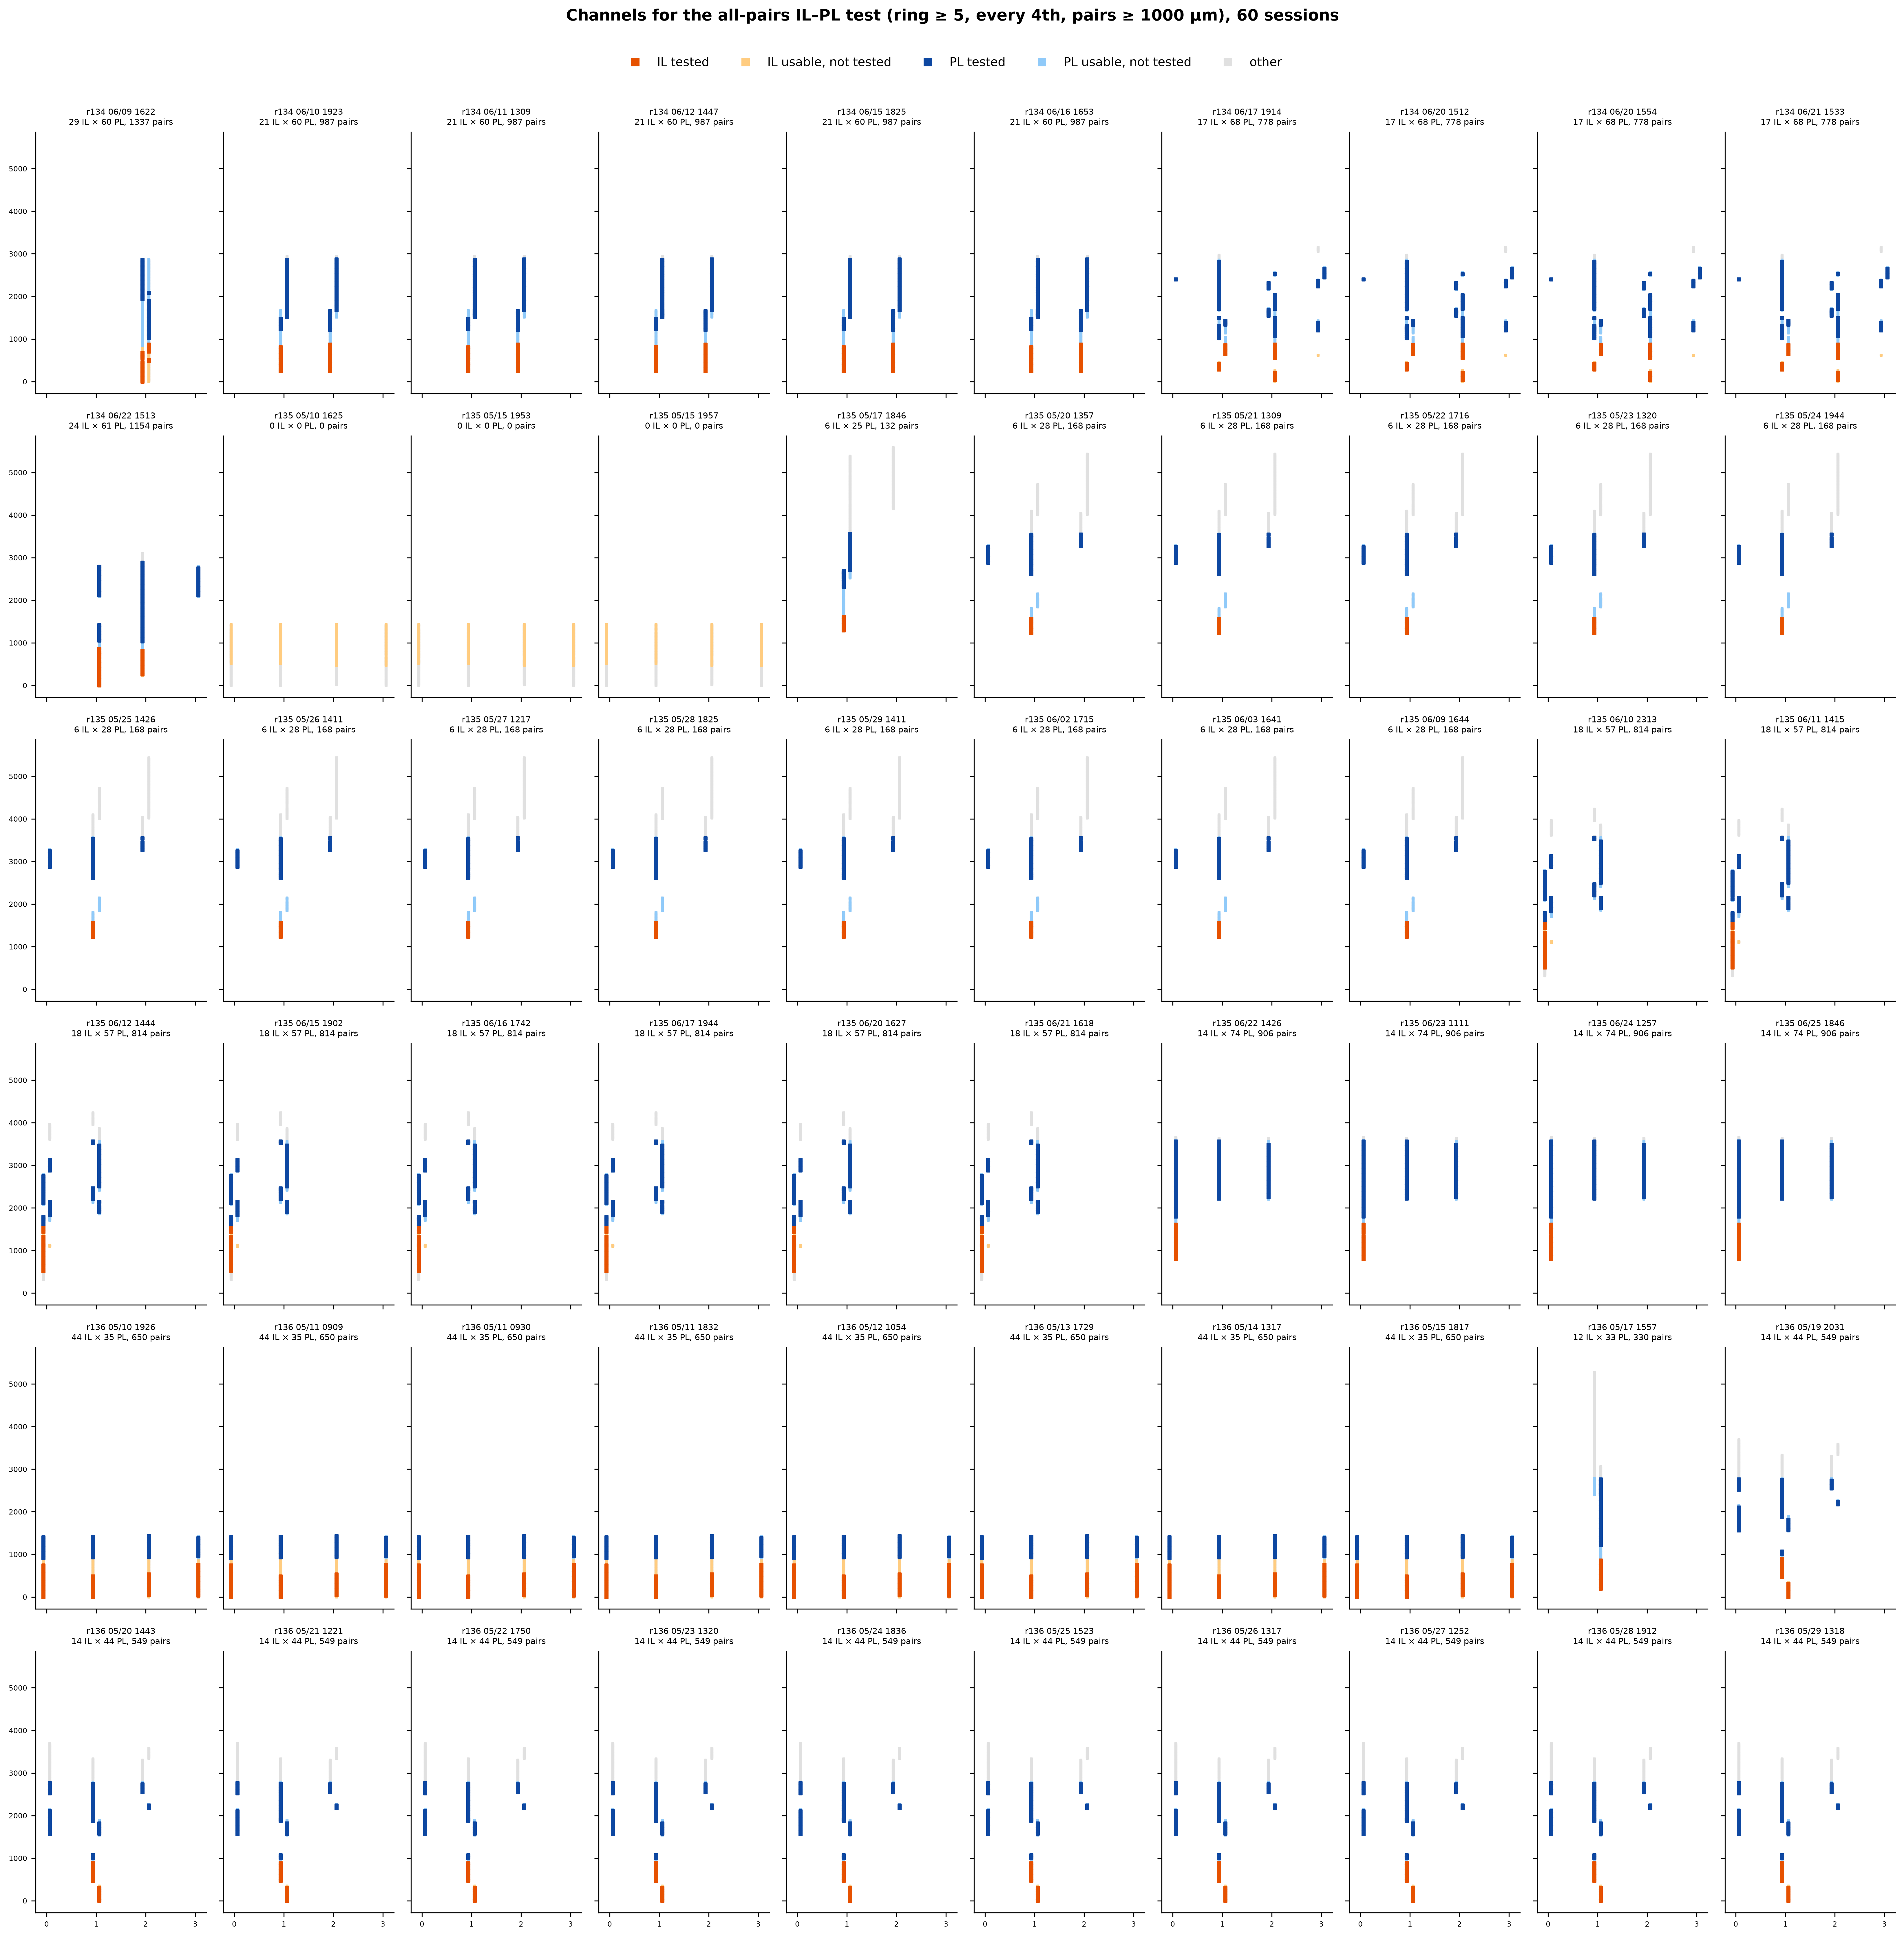

saved: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\amir_data\Theta\Phase connectivity\All sessions all pairs\all_pairs_channels_per_session.png


In [11]:
# ── 06 (independent): CHANNELS FOR THE ALL-PAIRS TEST — per session: usable IL / PL (ring ≥ 5), every 4th, pairs ≥ 1000 µm — table + one panel per session ──
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
DATA_ROOT = r"O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data"              # same as 06 cell 0
OUT = os.path.join(DATA_ROOT, "amir_data", "Theta", "Phase connectivity", "All sessions all pairs"); os.makedirs(OUT, exist_ok=True)
CHREG = pd.read_csv(os.path.join(TABLES, "channel_regions_all.csv")); CHREG["channel_id"] = CHREG["channel_id"].astype(str)
if "final" in globals(): CHREG = CHREG[CHREG.session.isin(final["session"])]
XB_ = pd.read_csv(os.path.join(TABLES, "extra_bad_channels.csv")); XB_["channel_id"] = XB_["channel_id"].astype(str)
bad = set(zip(XB_.session, XB_.channel_id))
CHREG = CHREG[[(s, c) not in bad for s, c in zip(CHREG.session, CHREG.channel_id)]]
SHORT = {"Infralimbic area": "IL", "Prelimbic area": "PL", "Cingulate area 1": "Cg1"}
CHREG["reg"] = CHREG["region"].map(SHORT).fillna("other"); CHREG["rat"] = CHREG["rat"].astype(str)
RING, MIN_RING, STRIDE, MIN_PAIR_UM, SHANK_W = (30, 500), 5, 4, 1000, 250
DCOL = {"IL": "#e65100", "PL": "#0d47a1"}; LCOL = {"IL": "#ffcc80", "PL": "#90caf9"}

def select(d):
    """usable channels (ring >= MIN_RING), every STRIDE-th per region (sorted shank, depth, x), and only those with a partner >= MIN_PAIR_UM"""
    x, y, reg = d.x.values, d.y.values, d.reg.values
    use = {}
    for g in ("IL", "PL"):
        idx = [i for i in np.where(reg == g)[0]
               if ((reg == g) & (np.hypot(x - x[i], y - y[i]) > RING[0]) & (np.hypot(x - x[i], y - y[i]) <= RING[1])).sum() >= MIN_RING]
        use[g] = (idx, sorted(idx, key=lambda i: (x[i] // SHANK_W, y[i], x[i]))[::STRIDE])
    il, pl = use["IL"][1], use["PL"][1]
    D = np.hypot(x[il][:, None] - x[pl][None, :], y[il][:, None] - y[pl][None, :]) if il and pl else np.zeros((len(il), len(pl)))
    M = D >= MIN_PAIR_UM
    il_t = [i for k, i in enumerate(il) if M[k].any()] if M.size else []; pl_t = [j for k, j in enumerate(pl) if M[:, k].any()] if M.size else []
    return use, il_t, pl_t, int(M.sum())

rows, GEO = [], {}
for s, d in CHREG.groupby("session"):
    d = d.reset_index(drop=True); use, il_t, pl_t, npairs = select(d)
    rows.append(dict(session=s, rat=d.rat.iloc[0], IL_usable=len(use["IL"][0]), PL_usable=len(use["PL"][0]),
                     IL_tested=len(il_t), PL_tested=len(pl_t), pairs=npairs))
    GEO[s] = (d, use, il_t, pl_t)
SEL = pd.DataFrame(rows); pd.set_option("display.width", 250); pd.set_option("display.max_rows", 100)
print(SEL.to_string(index=False))
print("\nper rat:"); print(SEL.groupby("rat").agg(sessions=("session", "size"), with_pairs=("pairs", lambda v: int((v > 0).sum())),
                                                 median_IL=("IL_tested", "median"), median_PL=("PL_tested", "median"), median_pairs=("pairs", "median")).to_string())
print("\nsessions with 0 pairs:", list(SEL.loc[SEL.pairs == 0, "session"]) or "none")
SEL.to_csv(os.path.join(OUT, "all_pairs_channels_per_session.csv"), index=False)

# ── figure: one panel per session, grouped by rat ──
SS = SEL.sort_values(["rat", "session"]).session.tolist(); nc = 10; nr = int(np.ceil(len(SS) / nc))
fig, axs = plt.subplots(nr, nc, figsize=(2.2 * nc, 3.6 * nr), facecolor="white", sharex=True, sharey=True)
for ax, s in zip(axs.flat, SS):
    d, use, il_t, pl_t = GEO[s]
    ax.scatter(d.x, d.y, marker="s", s=2, color="0.88", zorder=1)
    for g, t in (("IL", il_t), ("PL", pl_t)):
        u = [i for i in use[g][0] if i not in t]
        ax.scatter(d.x[u], d.y[u], marker="s", s=2, color=LCOL[g], zorder=2)
        ax.scatter(d.x[t], d.y[t], marker="s", s=6, color=DCOL[g], zorder=3)
    r_ = SEL[SEL.session == s].iloc[0]
    ax.set_title(f"r{r_.rat} {s[4:6]}/{s[6:8]} {s[-4:]}\n{r_.IL_tested} IL × {r_.PL_tested} PL, {r_.pairs} pairs", fontsize=7)
    ax.set_xticks([16, 266, 516, 766]); ax.set_xticklabels(["0", "1", "2", "3"], fontsize=6); ax.tick_params(labelsize=6)
    for sp in ("top", "right"): ax.spines[sp].set_visible(False)
for ax in axs.flat[len(SS):]: ax.axis("off")
fig.legend(handles=[plt.Line2D([], [], marker="s", ls="", color=DCOL["IL"], label="IL tested"), plt.Line2D([], [], marker="s", ls="", color=LCOL["IL"], label="IL usable, not tested"),
                    plt.Line2D([], [], marker="s", ls="", color=DCOL["PL"], label="PL tested"), plt.Line2D([], [], marker="s", ls="", color=LCOL["PL"], label="PL usable, not tested"),
                    plt.Line2D([], [], marker="s", ls="", color="0.88", label="other")], loc="upper center", ncol=5, frameon=False, bbox_to_anchor=(0.5, 1.01))
fig.suptitle(f"Channels for the all-pairs IL–PL test (ring ≥ {MIN_RING}, every {STRIDE}th, pairs ≥ {MIN_PAIR_UM} µm), {len(SS)} sessions",
             fontsize=13, fontweight="bold", y=1.03)
fig.tight_layout()
fp = os.path.join(OUT, "all_pairs_channels_per_session.png")
fig.savefig(fp, dpi=300, facecolor="white", bbox_inches="tight"); plt.close(fig); display(Image(fp))
print("saved:", fp)

In [1]:
# ── 5l. BETA POWER 15–30 Hz, NORMALISED TO THE 90th PERCENTILE (Karvat 2021), REPRESENTATIVE CHANNELS, LOCAL — ALL SESSIONS ──
import os, sys, time, importlib, warnings
import numpy as np, pandas as pd
import scipy.signal as ss
MAIN = r"C:\Users\ar687\Documents\GitHub\AmirAnalysis\main"
sys.path.insert(0, MAIN)
import functions as fn
importlib.reload(fn)
warnings.filterwarnings("ignore", message="The following channels did not have enough neighbors")

DATA_ROOT = r"O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data"
DATA_OUT  = os.path.join(DATA_ROOT, "amir_data", "data")
PROC      = os.path.join(DATA_ROOT, "2_processed")
TABLES    = os.path.join(MAIN, "tables")
BURST_DIR = os.path.join(DATA_OUT, "Bursts detection")                     # channels + trial order (same as the bursts)
OUT_DIR   = os.path.join(DATA_OUT, "Beta power p90 LOCAL"); os.makedirs(OUT_DIR, exist_ok=True)
XB        = pd.read_csv(os.path.join(TABLES, "extra_bad_channels.csv"))

REF, REGS   = "LOCAL", ("IL", "PL", "Cg1")
FREQS, NCYC = np.arange(15, 31), 7                                          # as fn.BURST_BANDS["beta 15-30"]
T0, T1, STEP = -1.0, 0.5, 0.010                                             # around the tone, 10-ms steps
OVERWRITE = False

sessions = sorted(f[:-4] for f in os.listdir(BURST_DIR) if f.endswith(".npz") and not f.endswith(".tmp.npz"))
todo = [s for s in sessions if OVERWRITE or not os.path.exists(os.path.join(OUT_DIR, s + ".npz"))]
print(f"{len(sessions)} sessions, {len(todo)} to do -> {OUT_DIR}", flush=True)
t_start = time.time()
for n_, s in enumerate(todo, 1):
    t_s = time.time()
    try:
        zb  = np.load(os.path.join(BURST_DIR, s + ".npz"))
        ch  = {g: str(zb[f"{REF}|{g}|channel"][0]) for g in REGS if f"{REF}|{g}|channel" in zb.files}
        T   = pd.read_csv(os.path.join(BURST_DIR, s + "_trials.csv"))       # same rows as the burst file
        rec = fn.load_session(PROC, s, XB, refs=(REF,))[0][REF]; fs = rec.get_sampling_frequency()
        X   = fn.read_full(rec, list(ch.values()))
        off = np.round(np.arange(T0, T1 + 1e-9, STEP) * fs).astype(int)
        res = {"times": off / fs, "freqs": FREQS}
        for j, (g, cid) in enumerate(ch.items()):
            x   = X[:, j]
            art = fn._ndi_dilate(np.abs(x) > fn.BURST_ART_UV, fn.BURST_ART_PAD)
            B   = np.zeros(len(x), np.float32)
            for f in FREQS:
                p = (np.abs(ss.fftconvolve(x, fn.morlet(f, NCYC, fs), mode="same")) ** 2).astype(np.float32)
                p[art] = np.nan
                B += p / np.nanpercentile(p, 90)                             # fraction of the 90th percentile (artifact-free)
            B /= len(FREQS)
            M = np.full((len(T), len(off)), np.nan, np.float32)
            for k, t in enumerate(T["tone_s"].values.astype(float)):
                if not np.isfinite(t): continue
                idx = int(round(t * fs)) + off
                if idx[0] >= 0 and idx[-1] < len(B): M[k] = B[idx]
            res[f"{g}|tone"], res[f"{g}|channel"] = M, np.array([cid])
            res[f"{g}|artifact_frac"] = np.array([art.mean()])
        del X
        tmp = os.path.join(OUT_DIR, s + ".tmp.npz")
        np.savez_compressed(tmp, **res); os.replace(tmp, os.path.join(OUT_DIR, s + ".npz"))
        print(f"[{n_}/{len(todo)}] {s}: ok {list(ch)} ({(time.time() - t_s) / 60:.1f} min)", flush=True)
    except Exception as e:
        print(f"[{n_}/{len(todo)}] {s}: ERROR {e!r}", flush=True)
print(f"finished in {(time.time() - t_start) / 60:.0f} min", flush=True)

60 sessions, 59 to do -> O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\amir_data\data\Beta power p90 LOCAL
[1/59] 20260510_r0000136_wt_1926: ok ['IL', 'PL'] (0.7 min)
[2/59] 20260511_r0000136_wt_0909: ok ['IL', 'PL'] (0.2 min)
[3/59] 20260511_r0000136_wt_0930: ok ['IL', 'PL'] (0.4 min)
[4/59] 20260511_r0000136_wt_1832: ok ['IL', 'PL'] (0.6 min)
[5/59] 20260512_r0000136_wt_1054: ok ['IL', 'PL'] (0.7 min)
[6/59] 20260513_r0000136_wt_1729: ok ['IL', 'PL'] (0.2 min)
[7/59] 20260514_r0000136_wt_1317: ok ['IL', 'PL'] (0.6 min)
[8/59] 20260515_r0000135_wt_1953: ok ['IL'] (0.8 min)
[9/59] 20260515_r0000135_wt_1957: ok ['IL'] (0.4 min)
[10/59] 20260515_r0000136_wt_1817: ok ['IL', 'PL'] (0.9 min)
[11/59] 20260517_r0000135_wt_1846: ok ['IL', 'PL', 'Cg1'] (1.0 min)
[12/59] 20260517_r0000136_wt_1557: ok ['IL', 'PL', 'Cg1'] (1.0 min)
[13/59] 20260519_r0000136_wt_2031: ok ['IL', 'PL', 'Cg1'] (1.0 min)
[14/59] 20260520_r0000135_wt_1357: ok ['IL', 'PL', 'Cg1'] (0.7 min)
[15/59] 20260520_r0000